# Projekt 3 - Regresja Liniowa Prosta & Regresja wieloraka

# Regresja Liniowa Prosta

## 1. Opis danych i ich źródło

**Źródło danych:**  
UC Irvine Machine Learning Repository - **Combined Cycle Power Plant Data Set**  
*https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant*

**Autorzy zbioru:** Pınar Tüfekci, Heysem Kaya 

**Opis:**  
Zbiór zawiera 9 568 punktów danych zebranych z elektrowni gazowo-parowej (Combined Cycle Power Plant - CCPP) przez 6 lat (2006-2011), gdy elektrownia pracowała przy pełnym obciążeniu. Dane reprezentują godzinowe średnie wartości zmiennych środowiskowych.

Elektrownia gazowo-parowa (CCPP) składa się z turbin gazowych (GT), turbin parowych (ST) oraz parowych generatorów odzysku ciepła. Elektryczność jest generowana przez turbiny gazowe i parowe połączone w jednym cyklu. Podciśnienie (V) jest zbierane przez turbinę parową i na nią oddziałuje, natomiast pozostałe trzy zmienne środowiskowe (AT, AP, RH) wpływają na wydajność turbiny gazowej (GT).

**Zmienne:**
- **AT** - Temperatura otoczenia (stopnie Celsjusza), zakres: 1.81 - 37.11
- **V** - Podciśnienie spalin (cm Hg)
- **AP** - Ciśnienie atmosferyczne (mbar)
- **RH** - Wilgotność względna (%)
- **PE** - **Zmienna zależna (Y)** - Moc wyjściowa netto elektrowni (MW)

**W modelu regresji prostej:**
- **X = AT** (temperatura otoczenia) - główny czynnik wpływający na moc turbiny
- **Y = PE** (moc wyjściowa netto)

**Liczba obserwacji:** 9 568 

**Uzasadnienie wyboru zmiennych:**  
Wyższa temperatura otoczenia zmniejsza gęstość powietrza wchodzącego do turbiny gazowej, co bezpośrednio obniża jej moc. Zależność ta powinna dawać czytelną, silną korelację liniową.

**Format danych:**  
Dane dostępne są w formacie .xlsx. Plik Folds5x2_pp.xlsx zawiera 5 arkuszy z przemieszanymi danymi (5×2-krotna kroswalidacja). W niniejszej analizie wykorzystano dane z pierwszego arkusza.

## 2. Opis teoretyczny modelu regresji liniowej prostej

Model regresji liniowej prostej opisuje liniową zależność między zmienną objaśnianą $Y$ a jedną zmienną objaśniającą $X$:

$$Y_i = a \cdot X_i + b, \quad i = 1, 2, \ldots, n$$

gdzie:
- $a$ - współczynnik kierunkowy (nachylenie prostej),<br> interpretacja: wzrost $X$ o 1 jednostkę powoduje zmianę $Y$ o $a$ jednostek,
- $b$ - wyraz wolny (intercept), wartość $Y$ gdy $X = 0$,


### Metoda najmniejszych kwadratów (MNK)

Szacujemy parametry minimalizując sumę kwadratów reszt:

$$f(a, b) = \sum_{i=1}^n (Y_i - \hat{Y}_i)^2 = \sum_{i=1}^n (Y_i - a X_i - b)^2$$

Analityczne rozwiązanie (pochodne cząstkowe = 0):

$$\hat{a} = \frac{\sum_{i=1}^n (Y_i - \bar{Y})(X_i - \bar{X})}{\sum_{i=1}^n (X_i - \bar{X})^2}, \qquad \hat{b} = \bar{Y} - \hat{a}\bar{X}$$

### Założenia modelu
1. Liniowość zależności między $X$ a $Y$
2. Normalność reszt
3. Brak trendów w resztach
4. Analiza regresji nie powinna być ekstrapolowana
5. Co najmnie 30 obserwacji do stworzenia modelu (zalecane)
6. Homoskedastyczność: stała wariancja reszt 
7. Brak autokorelacji reszt
8. Brak wartości wpływowych zaburzających model

### Miary jakości modelu
- **R²** - współczynnik determinacji - odsetek wyjaśnionej wariancji zmiennej $Y$ (0-1, im wyższy tym lepiej)
- **RSE** - resztowe odchylenie standardowe (Residual Standard Error)
- **RMSE** - pierwiastek błędu średniokwadratowego: $\text{RMSE} = \sqrt{\frac{1}{n}\sum_i(Y_i - \hat{Y}_i)^2}$

## 3. Analiza modelu

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.gofplots import ProbPlot

### 3.1 Analiza opisowa i EDA

Wczytanie danych

In [2]:
df = pd.read_excel('CCPP/Folds5x2_pp.xlsx') 

print(f"Kształt danych: {df.shape}")
print(f"\nKolumny: {list(df.columns)}")
df.head(10)

Kształt danych: (9568, 5)

Kolumny: ['AT', 'V', 'AP', 'RH', 'PE']


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90
5,26.27,59.44,1012.23,58.77,443.67
6,15.89,43.96,1014.02,75.24,467.35
7,9.48,44.71,1019.12,66.43,478.42
8,14.64,45.00,1021.78,41.25,475.98
9,11.74,43.56,1015.14,70.72,477.50


Podstawowe statystyki opisowe

In [ ]:
df.describe().round(4)

,AT,V,AP,RH,PE
count,9568.0000,9568.0000,9568.0000,9568.0000,9568.000
mean,19.6512,54.3058,1013.2591,73.3090,454.365
std,7.4525,12.7079,5.9388,14.6003,17.067
min,1.8100,25.3600,992.8900,25.5600,420.260
25%,13.5100,41.7400,1009.1000,63.3275,439.750
50%,20.3450,52.0800,1012.9400,74.9750,451.550
75%,25.7200,66.5400,1017.2600,84.8300,468.430
max,37.1100,81.5600,1033.3000,100.1600,495.760


Sprawdzenie braków danych

In [4]:
print(df.isnull().sum())

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


Zbiór danych jest kompletny, żadna ze zmiennych nie zawiera brakujących wartości.

Zmienne modelu

In [5]:
X = df['AT']  # temperatura otoczenia
Y = df['PE']  # moc wyjściowa

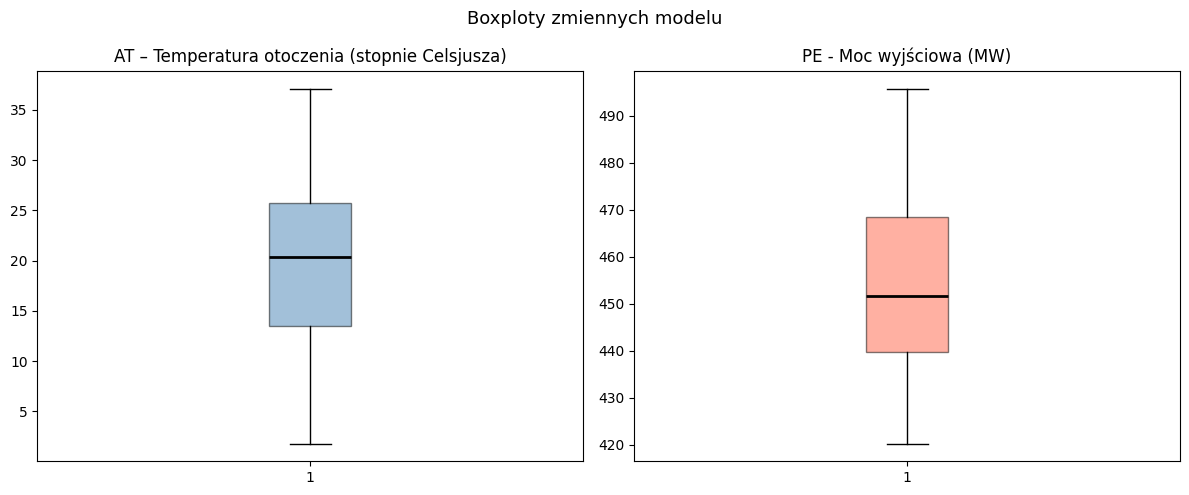

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col, label, color in zip(
    axes,
    [X, Y],
    ['AT - Temperatura otoczenia (stopnie Celsjusza)', 'PE - Moc wyjściowa (MW)'],
    ['steelblue', 'tomato']
):
    ax.boxplot(col, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.5),
               medianprops=dict(color='black', linewidth=2),
               flierprops=dict(marker='o', markerfacecolor=color, markersize=3, alpha=0.4))
    ax.set_title(label)

plt.suptitle('Boxploty zmiennych modelu', fontsize=13)
plt.tight_layout()
plt.show()

 Obie zmienne nie wykazują wartości odstających , co świadczy o dobrej jakości danych i braku konieczności wstępnego czyszczenia zbioru.

Wykres punktowy 

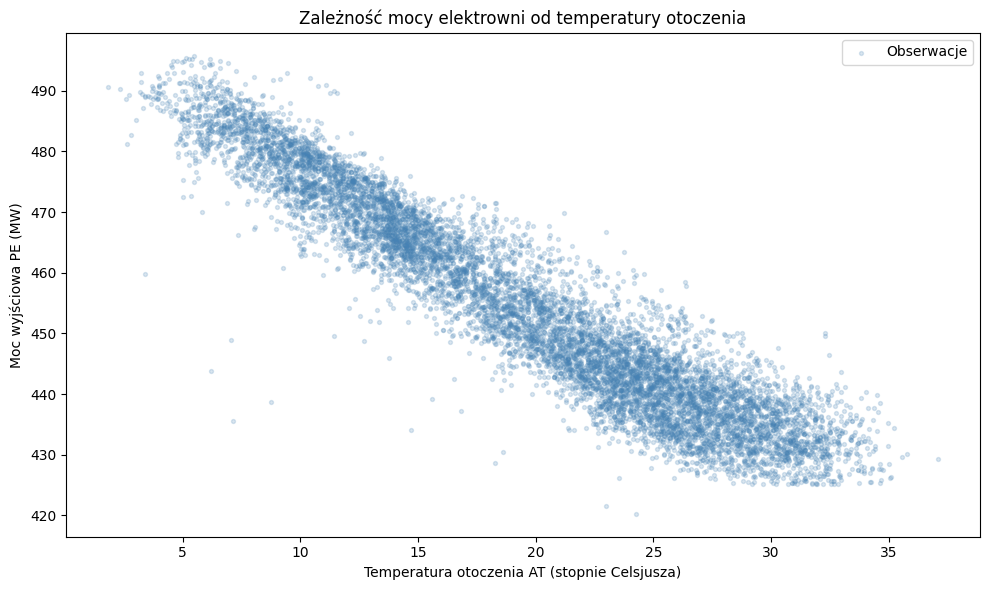

In [7]:
plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.2, s=8, color='steelblue', label='Obserwacje')
plt.xlabel('Temperatura otoczenia AT (stopnie Celsjusza)')
plt.ylabel('Moc wyjściowa PE (MW)')
plt.title('Zależność mocy elektrowni od temperatury otoczenia')
plt.legend()
plt.tight_layout()
plt.show()

Widoczna jest wyraźna, ujemna zależność liniowa między temperaturą otoczenia (AT) a mocą wyjściową elektrowni (PE) - wraz ze wzrostem temperatury moc elektrowni maleje, co jest zgodne z fizyką turbiny gazowej.

Współczynnik korelacji Pearsona 

In [8]:
r = np.corrcoef(X, Y)[0, 1]
print(f"Współczynnik korelacji Pearsona r = {r:.4f}")

Współczynnik korelacji Pearsona r = -0.9481


 Bardzo silna ujemna korelacja liniowa między AT a PE potwierdza zasadność wyboru tych zmiennych do modelu regresji prostej.

### 3.2 Budowa modelu regresji liniowej 

In [9]:
X_const = sm.add_constant(X)  # dodanie intercept 
model = sm.OLS(Y, X_const).fit()

# współczynniki
b = model.params['const']
a = model.params['AT']

print(f"Współczynnik kierunkowy a = {a:.4f}")
print(f"Wyraz wolny b = {b:.4f}")
print(f"\nRównanie modelu: PE = {a:.4f} * AT + {b:.4f}")

Współczynnik kierunkowy a = -2.1713
Wyraz wolny b = 497.0341

Równanie modelu: PE = -2.1713 * AT + 497.0341


- **Współczynnik kierunkowy a = -2.1713** <br> Wzrost temperatury otoczenia o 1 stopień Celsjusza powoduje średni spadek mocy wyjściowej elektrowni o 2.1713 MW. Znak ujemny jest zgodny z fizyką - wyższa temperatura zmniejsza gęstość powietrza zasilającego turbinę gazową, obniżając jej wydajność.
- **Wyraz wolny b = 497.0341** <br> Przy temperaturze otoczenia równej 0 stopni Celsjusza model przewiduje moc wyjściową równą 497.03 MW. Wartość ta ma ograniczoną interpretację praktyczną, ponieważ AT = 0°C leży poza zakresem danych treningowych (1.81-37.11°C), jednak jest matematycznie spójna z obserwowanymi wartościami PE (420-496 MW).

Wykres z dopasowaną prostą

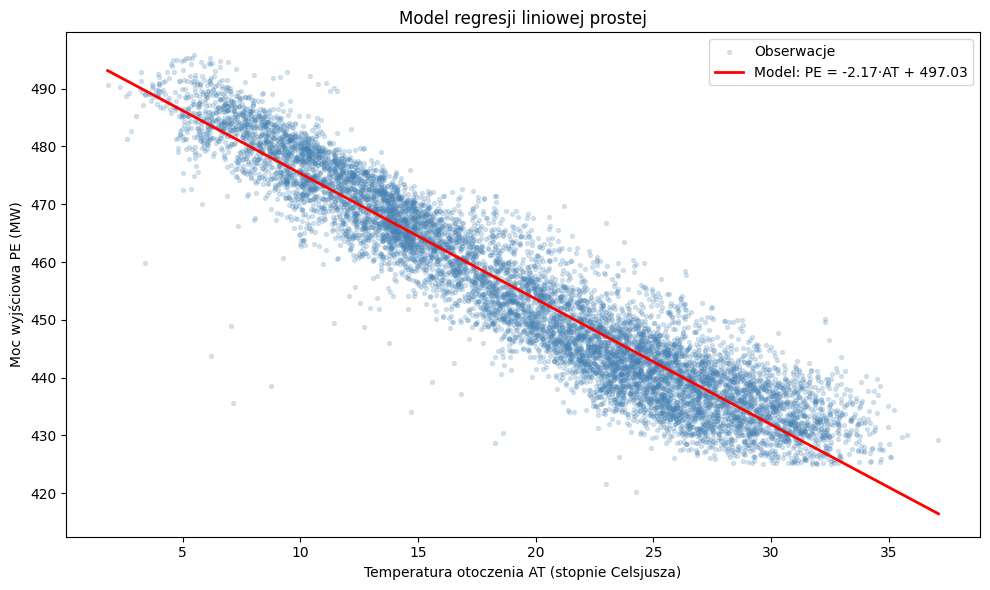

In [10]:
x_line = np.linspace(X.min(), X.max(), 300)
y_line = a * x_line + b

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.2, s=8, color='steelblue', label='Obserwacje')
plt.plot(x_line, y_line, color='red', linewidth=2, label=f'Model: PE = {a:.2f}·AT + {b:.2f}')
plt.xlabel('Temperatura otoczenia AT (stopnie Celsjusza)')
plt.ylabel('Moc wyjściowa PE (MW)')
plt.title('Model regresji liniowej prostej')
plt.legend()
plt.tight_layout()
plt.show()

### 3.3 Podsumowanie modelu 

In [11]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                 8.510e+04
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        11:52:52   Log-Likelihood:                -29756.
No. Observations:                9568   AIC:                         5.952e+04
Df Residuals:                    9566   BIC:                         5.953e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        497.0341      0.156   3177.280      0.0

In [14]:
n = len(Y)
resid = model.resid

# RSE 
RSE = np.sqrt(np.sum(resid**2) / (n - 2))
# RMSE
RMSE = np.sqrt(np.mean(resid**2))

print("Pozostałe miary dopasowania")
print(f"RSE: {RSE:.4f} MW")
print(f"RMSE: {RMSE:.4f} MW")

print("\nResiduals (reszty)")
print(f"Min: {resid.min():.4f}")
print(f"Q1: {resid.quantile(0.25):.4f}")
print(f"Median: {resid.median():.4f}")
print(f"Q3: {resid.quantile(0.75):.4f}")
print(f"Max: {resid.max():.4f}")




Pozostałe miary dopasowania
RSE: 5.4257 MW
RMSE: 5.4251 MW

Residuals (reszty)
Min: -45.9509
Q1: -3.6436
Median: 0.1009
Q3: 3.6960
Max: 23.2512


**Istotność współczynników:**<br>
Oba współczynniki mają p-value = 0.00 (< 0.05), co oznacza, że są wysoce istotne statystycznie - zmienna AT wnosi istotną informację wyjaśniającą zmienność PE.

**Przedziały ufności (95%):**<br>
Przedział dla **a** wynosi [-2.186, -2.157] - jest wąski i nie zawiera zera, co potwierdza istotność współczynnika kierunkowego. Analogicznie dla **b**: [496.727, 497.341].

**R^2 = 0.899:**<br>
Model wyjaśnia 89.9% zmienności mocy wyjściowej PE za pomocą samej temperatury AT - jest to bardzo dobry wynik dla regresji prostej.

**RSE = 5.4257 MW:**<br>
Przeciętny błąd predykcji modelu wynosi ok. 5.43 MW, co stanowi niewielki odsetek zakresu zmiennej PE (zakres 75.5 MW) - błąd jest akceptowalnie mały.

**F-statistic = 8.510e+04, p-value = 0.00:** <br>
Model jako całość jest wysoce istotny statystycznie - zmienna AT znacząco poprawia predykcję PE względem modelu zerowego (samej średniej).

**Durbin-Watson = 2.033:**
Wartość bliska 2 wskazuje na brak autokorelacji reszt - założenie niezależności składników losowych raczej jest spełnione.

**Jarque-Bera, Omnibus (p = 0.00):**
Testy wskazują na odchylenie od normalności reszt (skośność = -0.209, kurtoza = 4.621 > 3). Przy tak dużej próbie (n=9568) testy są bardzo czułe na małe odchylenia.

### 3.4 Sprawdzenie założeń modelu

#### 3.4.1 Korelacja i istotność współczynnika korelacji
- H0: r = 0  
- H1: r != 0 

In [15]:
print(f"Współczynnik korelacji Pearsona r = {r:.4f}")

Współczynnik korelacji Pearsona r = -0.9481


In [18]:
# t = r / sqrt((1 - r^2) / (n - 2))
r2 = model.rsquared
t_cor = np.sqrt(r2) / np.sqrt((1 - r2) / (n - 2))
t_kryt = stats.t.ppf(1 - 0.05/2, df=n-2)

print(f"r = {np.sqrt(r2):.4f}")
print(f"t_obliczone = {t_cor:.4f}")
print(f"t_krytyczne = {t_kryt:.4f}  (alpha=0.05, df={n-2})")
if abs(t_cor) > t_kryt:
    print("Wniosek: ODRZUCENIE H0 (r=0) - korelacja jest istotna statystycznie.")
else:
    print("Wniosek: Brak podstaw do odrzucenia H0 - korelacja nieistotna.")

r = 0.9481
t_obliczone = 291.7152
t_krytyczne = 1.9602  (alpha=0.05, df=9566)
Wniosek: ODRZUCENIE H0 (r=0) - korelacja jest istotna statystycznie.


#### 3.4.2 Normalność reszt - test Shapiro-Wilka i QQ-plot

Test Shapiro-Wilka
- H0: reszty pochodzą z rozkładu normalnego
- H1: reszty nie pochodzą z rozkładu normalnego

In [52]:
# Uwaga: dla n > 5000 test Shapiro-Wilka może być niestabilny, dlatego zostanie uzyta próbka
np.random.seed(22)
resid_sample5000 = resid.sample(5000) 
resid_sample500 = resid.sample(500) 

stat_sw5000, p_sw5000 = stats.shapiro(resid_sample5000)
stat_sw500, p_sw500 = stats.shapiro(resid_sample500)

print("Wyniki testu dla próbki n=5000")
print(f"W = {stat_sw5000:.4f}, p-value = {p_sw5000:.4e}")

print("\nWyniki testu dla próbki n=500")
print(f"W = {stat_sw500:.4f}, p-value = {p_sw500:.4e}")


Wyniki testu dla próbki n=5000
W = 0.9886, p-value = 1.2156e-19

Wyniki testu dla próbki n=500
W = 0.9955, p-value = 1.5574e-01


Test Shapiro-Wilka daje rozbieżne wyniki w zależności od rozmiaru próbki: 
- dla n=5000 H0 zostaje odrzucona (p<0.05)
- dla n=500 brak podstaw do odrzucenia (p>0.05). 
Obie wartości statystyki W są jednak bliskie 1, co wskazuje na jedynie nieznaczne odchylenie od normalności. Przy dużych próbach test Shapiro-Wilka jest bardzo czuły nawet na minimalne odchylenia, dlatego wynik dla n=5000 należy traktować ostrożnie.

QQ-plot reszt

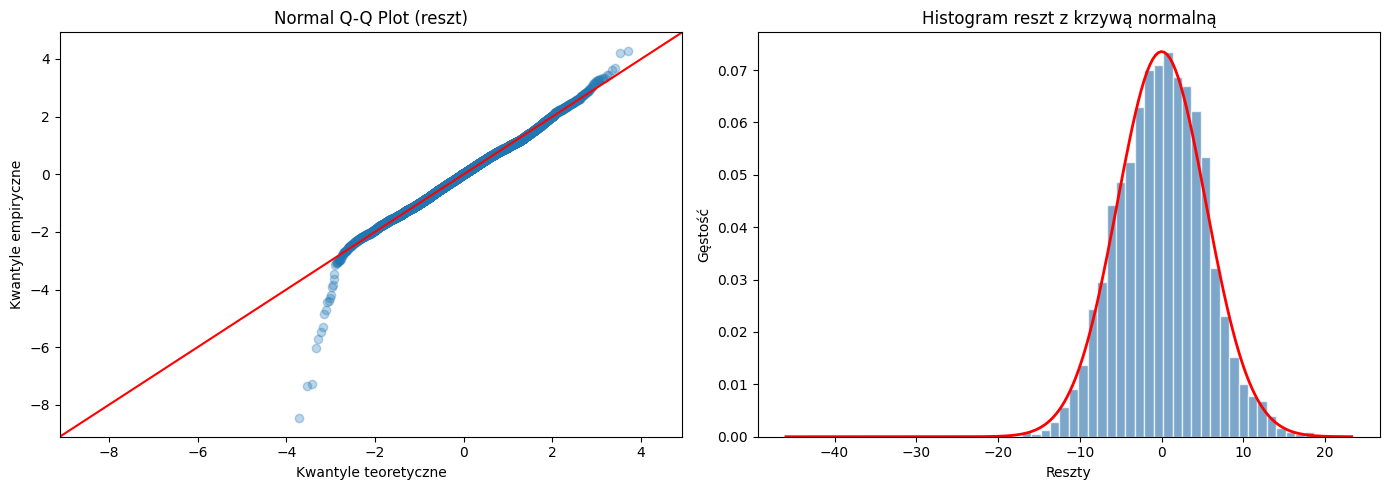

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# QQ-plot
pp = ProbPlot(resid, fit=True)
pp.qqplot(ax=axes[0], line='45', alpha=0.3, lw=1)
axes[0].set_title('Normal Q-Q Plot (reszt)')
axes[0].set_xlabel('Kwantyle teoretyczne')
axes[0].set_ylabel('Kwantyle empiryczne')

# Histogram reszt
axes[1].hist(resid, bins=60, density=True, color='steelblue', alpha=0.7, edgecolor='white')
x_norm = np.linspace(resid.min(), resid.max(), 200)
axes[1].plot(x_norm, stats.norm.pdf(x_norm, resid.mean(), resid.std()), 'r-', lw=2)
axes[1].set_title('Histogram reszt z krzywą normalną')
axes[1].set_xlabel('Reszty')
axes[1].set_ylabel('Gęstość')

plt.tight_layout()
plt.show()


**QQ-plot:**
Większość punktów leży bardzo blisko prostej 45 stopni, co wskazuje na przybliżoną normalność reszt. Widoczne jest jednak wyraźne odchylenie w lewym ogonie - kilka obserwacji znacznie poniżej prostej sugeruje lewostronne ogony rozkładu. Prawy ogon jest dobrze dopasowany.

**Histogram:**
Rozkład reszt jest lewostronnie skośny (skośność = -0.209 z summary) - większość reszt skupia się blisko zera po prawej stronie, natomiast lewy ogon jest wydłużony z kilkoma ekstremalnymi wartościami. 
<br>
Podsumowując reszty wykazują przybliżoną normalność w centralnej części rozkładu, jednak obecność lewostronnych wartości ekstremalnych narusza to założenie. Przy n=9568 model pozostaje jednak wiarygodny na mocy Centralnego Twierdzenia Granicznego - małe odchylenia od normalności przy tak dużej próbie mają minimalny wpływ na jakość estymacji.

#### 3.4.3 Brak trendu w resztach

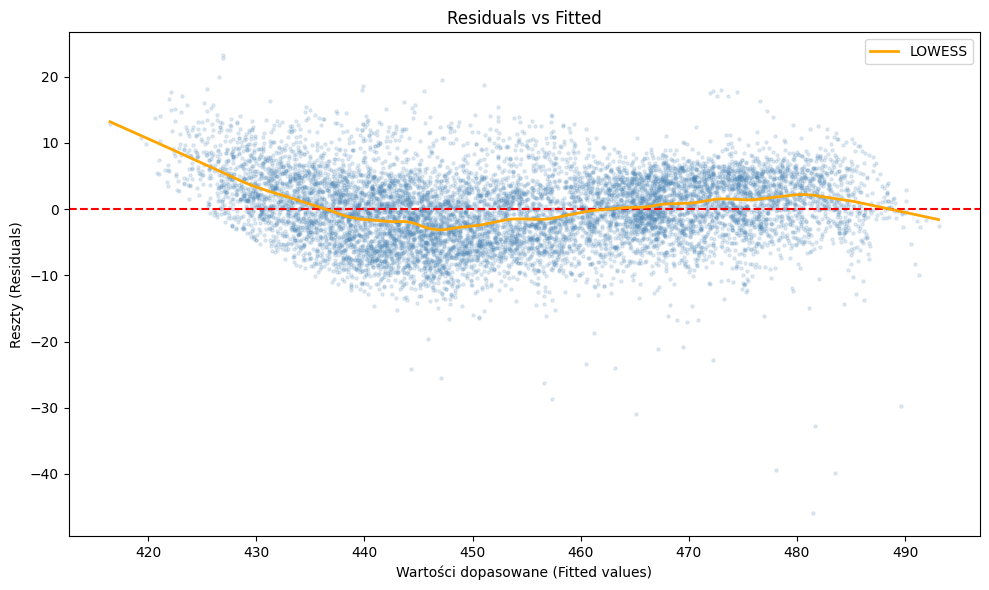

In [59]:
fitted = model.fittedvalues

# wykres reszt vs wartości dopasowanych 
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(fitted, resid, alpha=0.15, s=5, color='steelblue')
ax.axhline(0, color='red', linestyle='--', linewidth=1.5)

# wygładzona linia trendu
lowess = sm.nonparametric.lowess(resid, fitted, frac=0.1)
ax.plot(lowess[:, 0], lowess[:, 1], color='orange', linewidth=2, label='LOWESS')

ax.set_xlabel('Wartości dopasowane (Fitted values)')
ax.set_ylabel('Reszty (Residuals)')
ax.set_title('Residuals vs Fitted')
ax.legend()
plt.tight_layout()
plt.show()


Linia LOWESS nie jest pozioma - wykazuje wyraźną krzywizną, co wskazuje na nieidealne dopasowanie modelu liniowego i sugeruje, że prawdziwa zależność między AT a PE może mieć lekko nieliniowy charakter. Reszty nie układają się losowo wokół zera dla wszystkich wartości dopasowanych - przy niskich wartościach fitted (≈415-425 MW) reszty są dodatnie, w środkowym zakresie (≈435-460 MW) ujemne, a przy wysokich (≈465-485 MW) znów dodatnie.

Widoczna jest również asymetria rozrzutu - kilka ekstremalnych wartości ujemnych (do -45 MW), co koresponduje z lewostronnym ogonem zaobserwowanym na histogramie reszt.

Założenie liniowości jest częściowo naruszone - model liniowy dobrze opisuje ogólny trend, jednak nie wychwytuje pewnej nieliniowości w danych.

#### 3.4.4 Ekstrapolacja - przedział wartości, dla których model ma sens

In [60]:
print(f"Zakres zmiennej AT w danych: [{X.min():.2f}, {X.max():.2f}] stopni Celsjusza")
print(f"Zakres zmiennej PE w danych: [{Y.min():.2f}, {Y.max():.2f}] MW")

Zakres zmiennej AT w danych: [1.81, 37.11] stopni Celsjusza
Zakres zmiennej PE w danych: [420.26, 495.76] MW


Model regresji jest wiarygodny w zakresie obserwowanych danych: AT należące do [1.81, 37.11] stopni Celsjusza

Ekstrapolacja poza ten zakres jest nieuzasadniona.

Przy AT = 0 stopni Celsjusza model przewiduje 497.03 MW - wartość jest technicznie sensowna, ale AT = 0 leży poza zakresem danych, więc intercept pełni tylko rolę matematyczną.

#### 3.4.5 Liczba obserwacji

In [66]:
print(f"Liczba obserwacji: {len(df)}")

Liczba obserwacji: 9568


Zbiór zawiera 9568 obserwacji, zatem warunek minimum 30 jest spełniony. Wyniki modelu są wiarygodne statystycznie.

#### 3.4.6 Homoskedastyczność (stała wariancja reszt)
Scale-Location plot


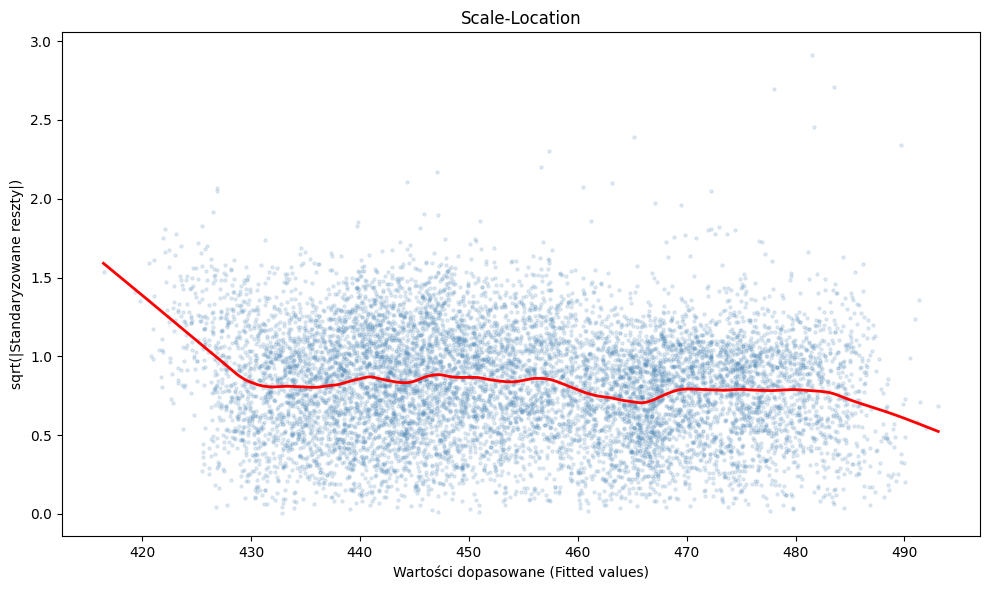

In [69]:
fig, ax = plt.subplots(figsize=(10, 6))
sqrt_abs_resid = np.sqrt(np.abs(resid / resid.std()))
ax.scatter(fitted, sqrt_abs_resid, alpha=0.15, s=5, color='steelblue')
lowess2 = sm.nonparametric.lowess(sqrt_abs_resid, fitted, frac=0.1)
ax.plot(lowess2[:, 0], lowess2[:, 1], color='red', linewidth=2)
ax.set_xlabel('Wartości dopasowane (Fitted values)')
ax.set_ylabel('sqrt(|Standaryzowane reszty|)')
ax.set_title('Scale-Location')
plt.tight_layout()
plt.show()


Na wykresie linia wykazuje trend malejący - można stwierdzić, że wariancja reszt nie jest stała - jest wyższa dla niskich wartości dopasowanych (niska moc, wysoka temperatura) i maleje dla wysokich.

Heteroskedastyczność zawyża precyzję oszacowanych współczynników, dlatego przedziały ufności i testy istotności należy traktować z ostrożnością. 

#### 3.4.7 Autokorelacja reszt - test Box-Pierce

- H0 : nie występują autokorelacja reszt
- H1: autokorelacja występuje

In [72]:
for lag in [1, 2, 3]:
    result = acorr_ljungbox(resid, lags=[lag], boxpierce=True, return_df=True)
    stat = result['bp_stat'].values[0]
    pval = result['bp_pvalue'].values[0]
    decision = "ODRZUCENIE H0 - autokorelacja reszt występuje" if pval < 0.05 else "Brak podstaw do odrzucenia H0"
    print(f"  lag={lag}: Q = {stat:.4f}, p-value = {pval:.4f} -> {decision}")

  lag=1: Q = 2.6123, p-value = 0.1060 -> Brak podstaw do odrzucenia H0
  lag=2: Q = 2.7359, p-value = 0.2546 -> Brak podstaw do odrzucenia H0
  lag=3: Q = 2.9429, p-value = 0.4005 -> Brak podstaw do odrzucenia H0


We wszystkich przypadkach p-value > 0.05, zatem nie ma podstaw do odrzucenia hipotezy zerowej o braku autokorelacji reszt. Założenie o braku autokorelacji reszt jest spełnione.

### 3.5 Wykresy diagnostyczne i wartości odstające

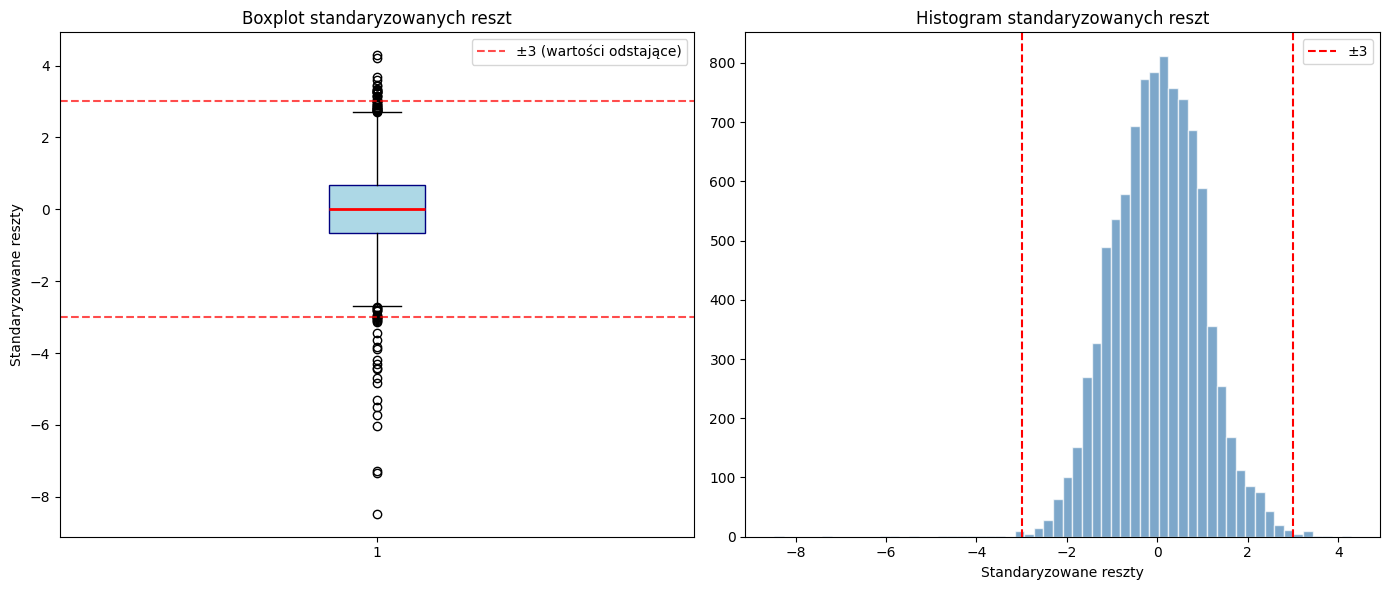

Liczba obserwacji odstających (|std_resid| > 3): 42
Odsetek: 0.44%


In [75]:
# standaryzowane reszty
influence = model.get_influence()
std_resid = influence.resid_studentized_internal

# boxplot standaryzowanych reszt 
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

bp = axes[0].boxplot(std_resid, patch_artist=True,
                      boxprops=dict(facecolor='lightblue', color='navy'),
                      medianprops=dict(color='red', linewidth=2))
axes[0].axhline(3, color='red', linestyle='--', alpha=0.7, label='±3 (wartości odstające)')
axes[0].axhline(-3, color='red', linestyle='--', alpha=0.7)
axes[0].set_title('Boxplot standaryzowanych reszt')
axes[0].set_ylabel('Standaryzowane reszty')
axes[0].legend()

# histogram standaryzowanych reszt
axes[1].hist(std_resid, bins=60, color='steelblue', alpha=0.7, edgecolor='white')
axes[1].axvline(3, color='red', linestyle='--', label='±3')
axes[1].axvline(-3, color='red', linestyle='--')
axes[1].set_title('Histogram standaryzowanych reszt')
axes[1].set_xlabel('Standaryzowane reszty')
axes[1].legend()

plt.tight_layout()
plt.show()

n_outliers = np.sum(np.abs(std_resid) > 3)
print(f"Liczba obserwacji odstających (|std_resid| > 3): {n_outliers}")
print(f"Odsetek: {n_outliers/n*100:.2f}%")

Spośród 9568 obserwacji jedynie 42 (0.44%) mają standaryzowaną resztę przekraczającą ±3. Odsetek ten jest niski i raczej nie wskazuje na poważny problem z wartościami odstającymi

### 3.6 Wartości wpływowe - odległość Cook'a

Próg odległości Cook'a: 0.000418


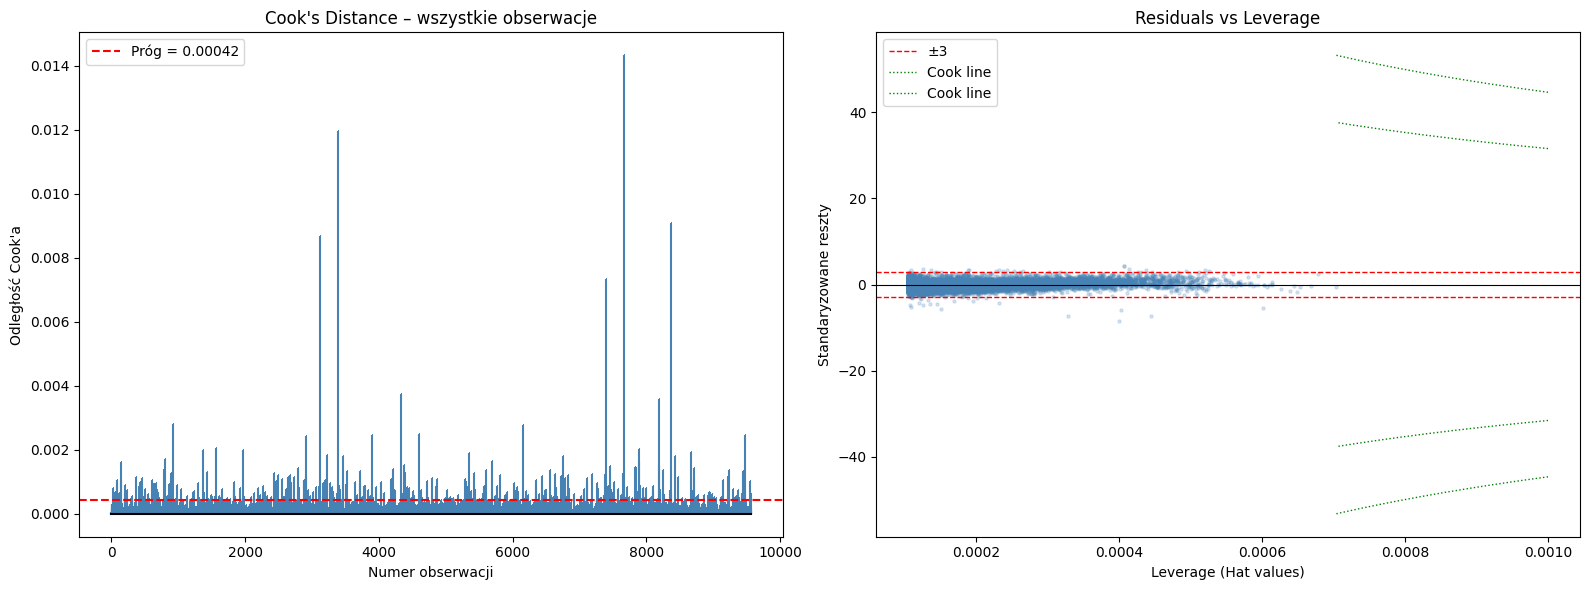


Liczba obserwacji wpływowych (Cook's D > 0.00042): 416
Odsetek: 4.35%


In [ ]:
p = 1  # liczba zmiennych niezależnych
hat_values = influence.hat_matrix_diag
cooks_d = influence.cooks_distance[0]

# próg dla odległości Cook'a: 4/(n-p-1)
cook_threshold = 4 / (n - p - 1)

print(f"Próg odległości Cook'a: {cook_threshold:.6f}")

# wykres Cook's Distance 
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].stem(np.arange(n), cooks_d, markerfmt=',', linefmt='steelblue',
             basefmt='black')
axes[0].axhline(cook_threshold, color='red', linestyle='--', linewidth=1.5, label=f'Próg = {cook_threshold:.5f}')
axes[0].set_xlabel('Numer obserwacji')
axes[0].set_ylabel("Odległość Cook'a")
axes[0].set_title("Cook's Distance - wszystkie obserwacje")
axes[0].legend()

# wykres Leverage vs Std Residuals 
axes[1].scatter(hat_values, std_resid, alpha=0.2, s=5, color='steelblue')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].axhline(3, color='red', linestyle='--', linewidth=1, label='±3')
axes[1].axhline(-3, color='red', linestyle='--', linewidth=1)
# linie Cook'a 0.5
h_range = np.linspace(0.001, hat_values.max(), 200)
for cook_level in [0.5, 1.0]:
    cook_line = np.sqrt(cook_level * 2 * (1 - h_range) / h_range)
    axes[1].plot(h_range, cook_line, 'g:', linewidth=1, label='Cook line')
    axes[1].plot(h_range, -cook_line, 'g:', linewidth=1)
axes[1].set_xlabel('Leverage (Hat values)')
axes[1].set_ylabel('Standaryzowane reszty')
axes[1].set_title("Residuals vs Leverage")
axes[1].legend()

plt.tight_layout()
plt.show()

influential_mask = cooks_d > cook_threshold
n_influential = influential_mask.sum()
print(f"\nLiczba obserwacji wpływowych (Cook's D > {cook_threshold:.5f}): {n_influential}")
print(f"Odsetek: {n_influential/n*100:.2f}%")

Próg odległości Cook'a wynosi 0.00042. Spośród 9568 obserwacji 416 (4.35%) przekracza ten próg, co kwalifikuje je jako obserwacje wpływowe. Maksymalna odległość Cook'a wynosi ~0.0145, co wskazuje że wpływ poszczególnych obserwacji jest umiarkowany, jednak ich łączna liczba jest na tyle duża, że warto je usunąć i sprawdzić czy model się poprawi.

Wartości leverage są bardzo małe (zakres 0.0001-0.0010), co jest typowe dla dużych zbiorów danych. Większość obserwacji skupia się blisko zera na obu osiach. Widocznych jest jednak kilka punktów przekraczających linię ±3 standaryzowanych reszt - są to obserwacje o dużych resztach, ale przy jednocześnie niskim leverage. Oznacza to, że są to wartości odstające, ale nie wpływowe tzn. nie zniekształcają znacząco współczynników modelu przez swoją pozycję na osi X. Żadna obserwacja nie przekracza linii Cook'a 0.5 ani 1.0 - brak wyraźnej odminacji nad modelem.

### 3.7 Nowy model po usunięciu wartości wpływowych

Usunięcie wartości wpływowych

In [80]:
df_clean = df[~influential_mask].copy().reset_index(drop=True)

print(f"Liczba obserwacji przed usunięciem: {n}")
print(f"Liczba obserwacji po usunięciu: {len(df_clean)}")
print(f"Usunięto {n - len(df_clean)} obserwacji wpływowych")

Liczba obserwacji przed usunięciem: 9568
Liczba obserwacji po usunięciu: 9152
Usunięto 416 obserwacji wpływowych


Nowy model

In [81]:

X2 = df_clean['AT']
Y2 = df_clean['PE']
X2_const = sm.add_constant(X2)
model2 = sm.OLS(Y2, X2_const).fit()

a2 = model2.params['AT']
b2 = model2.params['const']
R2_2 = model2.rsquared
RSE2 = np.sqrt(np.sum(model2.resid**2) / (len(Y2) - 2))

R2 = model.rsquared

print("\nPORÓWNANIE MODELI")
table = pd.DataFrame({
    "Miara": ["a", "b (intercept)", "R^2", "RSE"],
    "Model 1 (pełny)": [a, b, R2, RSE],
    "Model 2 (bez wpływowych)": [a2, b2, R2_2, RSE2]
})

table


PORÓWNANIE MODELI


,Miara,Model 1 (pełny),Model 2 (bez wpływowych)
0,a,-2.171320,-2.233630
1,b (intercept),497.034120,498.019561
2,R^2,0.898948,0.919620
3,RSE,5.425666,4.779588


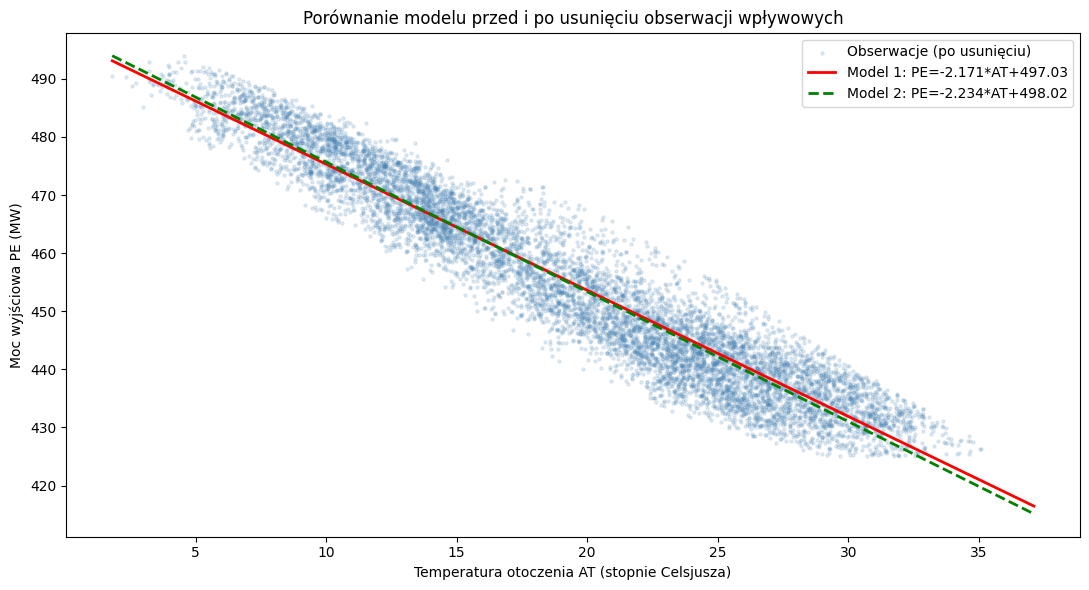

In [84]:
x_range = np.linspace(X.min(), X.max(), 300)

plt.figure(figsize=(11, 6))
plt.scatter(X2, Y2, alpha=0.15, s=5, color='steelblue', label='Obserwacje (po usunięciu)')
plt.plot(x_range, a * x_range + b, 'r-', lw=2, label=f'Model 1: PE={a:.3f}*AT+{b:.2f}')
plt.plot(x_range, a2 * x_range + b2, 'g--', lw=2, label=f'Model 2: PE={a2:.3f}*AT+{b2:.2f}')
plt.xlabel('Temperatura otoczenia AT (stopnie Celsjusza)')
plt.ylabel('Moc wyjściowa PE (MW)')
plt.title('Porównanie modelu przed i po usunięciu obserwacji wpływowych')
plt.legend()
plt.tight_layout()
plt.show()

Po usunięciu 416 obserwacji wpływowych model uległ poprawie:
- R^2 wzrósł z 0.8989 do 0.9196 - model wyjaśnia teraz 91.9% zmienności PE
- RSE spadł z 5.43 do 4.78 MW - przeciętny błąd predykcji zmniejszył się o ~0.65 MW
- Współczynniki zmieniły się nieznacznie (a: -2.171 -> -2.234, b: 497.03 -> 498.02) - ogólna struktura modelu pozostała stabilna.

### 3.8 Kroswalidacja 5-krotna (K-Fold Cross Validation)

In [87]:
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score

X_cv = df_clean['AT'].values
Y_cv = df_clean['PE'].values

# tasowanie danych przed podziałem (balansowanie zbiorów)
np.random.seed(42)
idx = np.random.permutation(len(X_cv))
X_cv = X_cv[idx]
Y_cv = Y_cv[idx]

# 5-krotna kroswalidacja (K=5, podział 80/20)
kf = KFold(n_splits=5, shuffle=False)

train_r2_list, test_r2_list = [], []
train_rse_list, test_rse_list = [], []

print("KROSWALIDACJA 5-KROTNA")
print(f"{'Fold':<6} {'R^2_train':<12} {'R^2_test':<12} {'RSE_train':<12} {'RSE_test':<12} {'n_train':<10} {'n_test'}")

for fold, (train_idx, test_idx) in enumerate(kf.split(X_cv), 1):
    X_train, X_test = X_cv[train_idx], X_cv[test_idx]
    Y_train, Y_test = Y_cv[train_idx], Y_cv[test_idx]
    
    # trenowanie modelu na 80% danych
    X_train_c = sm.add_constant(X_train)
    fold_model = sm.OLS(Y_train, X_train_c).fit()
    
    # predykcja na zbiorze treningowym
    Y_train_pred = fold_model.predict(X_train_c)
    r2_train = r2_score(Y_train, Y_train_pred)
    n_tr = len(Y_train)
    rse_train = np.sqrt(np.sum((Y_train - Y_train_pred)**2) / (n_tr - 2))
    
    # predykcja na zbiorze testowym (20%)
    X_test_c = sm.add_constant(X_test, has_constant='add')
    Y_test_pred = fold_model.predict(X_test_c)
    r2_test = r2_score(Y_test, Y_test_pred)
    n_te = len(Y_test)
    rse_test = np.sqrt(np.sum((Y_test - Y_test_pred)**2) / (n_te - 2))
    
    train_r2_list.append(r2_train)
    test_r2_list.append(r2_test)
    train_rse_list.append(rse_train)
    test_rse_list.append(rse_test)
    
    print(f"{fold:<8} {r2_train:<12.4f} {r2_test:<12.4f} {rse_train:<12.4f} {rse_test:<12.4f} {n_tr:<10} {n_te}")


KROSWALIDACJA 5-KROTNA
Fold   R^2_train    R^2_test     RSE_train    RSE_test     n_train    n_test
1        0.9207       0.9152       4.7404       4.9366       7321       1831
2        0.9192       0.9213       4.7957       4.7182       7321       1831
3        0.9200       0.9181       4.7768       4.7941       7322       1830
4        0.9195       0.9201       4.7892       4.7452       7322       1830
5        0.9188       0.9230       4.7953       4.7192       7322       1830


In [90]:
mean_r2_train = np.mean(train_r2_list)
mean_r2_test = np.mean(test_r2_list)
mean_rse_train = np.mean(train_rse_list)
mean_rse_test = np.mean(test_rse_list)
diff_r2 = mean_r2_train - mean_r2_test

print("PODSUMOWANIE KROSWALIDACJI")
print(f"Średnie R^2 treningowe: {mean_r2_train:.4f}")
print(f"Średnie R^2 testowe: {mean_r2_test:.4f}")
print(f"Różnica R^2 (train-test): {diff_r2:.4f}")
print(f"Średnie RSE treningowe: {mean_rse_train:.4f} MW")
print(f"Średnie RSE testowe: {mean_rse_test:.4f} MW")

PODSUMOWANIE KROSWALIDACJI
Średnie R^2 treningowe: 0.9196
Średnie R^2 testowe: 0.9195
Różnica R^2 (train-test): 0.0001
Średnie RSE treningowe: 4.7795 MW
Średnie RSE testowe: 4.7826 MW


Wyniki kroswalidacji są bardzo dobre i wskazują na brak przetrenowania.

Średnie R^2 treningowe i testowe są praktycznie identyczne (0.9196 vs 0.9195, różnica = 0.0001), co oznacza że model dobrze generalizuje na nowe dane. Analogicznie RSE treningowe i testowe są zbliżone (4.780 vs 4.782 MW). Wyniki są również bardzo stabilne między foldami - R^2 testowe waha się jedynie w zakresie 0.9152-0.9230, co świadczy o braku wrażliwości modelu na konkretny podział danych.

## 4. Wnioski i podsumowanie

Model regresji liniowej prostej PE ~ AT jest dobry, choć nie jest idealnym przybliżeniem zależności między temperaturą otoczenia a mocą wyjściową elektrowni gazowo-parowej.

Model 2 (po usunięciu obserwacji wpływowych) osiągnął R^2 = 0.920 i RSE = 4.78 MW, co oznacza że sama temperatura otoczenia wyjaśnia ponad 91% zmienności mocy wyjściowej - jest to dobry wynik dla regresji z jedną zmienną objaśniającą. Współczynnik kierunkowy a = -2.234 jest zgodny z fizyką i istotny statystycznie (p < 0.05).

Spełnienie założeń:

- Liniowość - potwierdzona silną korelacją Pearsona r = -0.948, jednak wykres Residuals vs Fitted ujawnia lekki trend krzywoliniowy - założenie liniowości jest częściowo naruszone
- Normalność reszt - lekko naruszona: QQ-plot wykazuje odchylenia w lewym ogonie, a testy Shapiro-Wilka i Jarque-Bera odrzucają normalność, ale przy n=9568 odchylenia te mają jednak minimalny wpływ na jakość estymacji (CTG)
- Brak autokorelacji - test Box-Pierce nie wykazał autokorelacji reszt dla żadnego opóźnienia
- Homoskedastyczność - wykryto heteroskedastyczność, wariancja reszt maleje wraz ze wzrostem wartości dopasowanych; przedziały ufności należy traktować z ostrożnością
- Brak dominujących obserwacji wpływowych - żadna obserwacja nie przekroczyła progu Cook'a 0.5, po usunięciu 416 obserwacji model lekko się poprawił.

Kroswalidacja:
Różnica między średnim R^2 treningowym a testowym wynosi zaledwie 0.0001, co jednoznacznie wskazuje na brak przetrenowania i dobrą generalizację modelu na nowe dane.

Ograniczenia:
Model jest stosowalny wyłącznie w zakresie AT należącym do [1.81, 37.11] stopni Celsjusza. Wykryta nieliniowość i heteroskedastyczność sugerują, że uwzględnienie pozostałych zmiennych (V, AP, RH) w modelu regresji wielorakiej mogłoby poprawić dopasowanie i wyeliminować część naruszeń założeń.

# Regresja wieloraka

## 1. Opis danych i ich źródło

**Źródło danych:**  
Diabetes Dataset sklearn

Dane udostępnione są również w bibliotece scikit-learn w wersji przeskalowanej. W niniejszej analizie wykorzystano wersję z oryginalnymi, nieprzeskalowanymi wartościami zmiennych, dostępną na platformie Kaggle:  
https://www.kaggle.com/datasets/antoniofurioso/diabetes-dataset-sklearn

**Opis:**  
Zbiór zawiera dane medyczne 442 pacjentów chorych na cukrzycę. Dla każdego pacjenta zmierzono 10 zmiennych bazowych, a zmienną zależną jest ilościowa miara postępu choroby po roku od badania bazowego.

**Zmienne:**
- AGE - wiek pacjenta (lata)
- SEX - płeć (1/2) - zostanie pominięta (zmienna kategoryczna)
- BMI - wskaźnik masy ciała
- BP - średnie ciśnienie krwi (mmHg)
- S1 - TC - całkowity cholesterol w surowicy (mg/dL)
- S2 - LDL - lipoproteiny niskiej gęstości (mg/dL)
- S3 - HDL - lipoproteiny wysokiej gęstości (mg/dL)
- S4 - TCH - stosunek całkowitego cholesterolu do HDL
- S5 - LTG - logarytm poziomu trójglicerydów w surowicy
- S6 - GLU - poziom glukozy we krwi (mg/dL)
- Y - **zmienna zależna** - ilościowa miara postępu cukrzycy po roku

W modelu regresji wielorakiej zostaną użyte (9 ciągłych zmiennych):<br> 
X = {AGE, BMI, BP, S1, S2, S3, S4, S5, S6}, Y = target

**Liczba obserwacji:** 442 (> 30 na każdą zmienną niezależną)

## 2. Opis teoretyczny modelu regresji liniowej wielorakiej

Gdy istnieje wiele predyktorów, równanie regresji rozszerza się do:

$$Y = a_1X_1 + a_2X_2 + \cdots + a_kX_k + a_0 $$

gdzie:
- $a_1, \ldots, a_k$  - współczynniki kierunkowe (przy stałości pozostałych zmiennych, wzrost $X_j$ o 1 jednostkę powoduje zmianę $Y$ o $a_j$),
- $a_0$  - wyraz wolny,

### Metoda najmniejszych kwadratów (MNK)

Minimalizujemy sumę kwadratów reszt:

$$f(a_0, a_1, \ldots, a_k) = \sum_{i=1}^n (Y_i - \hat{Y}_i)^2$$

### Założenia modelu
1. Liniowość zależności między $X_j$ a $Y$
2. Normalność reszt
3. Brak trendów w resztach
4. Analiza regresji nie powinna być ekstrapolowana 
5. Co najmnie 30 obserwacji  na zmienną niezależną (zalecane)
6. Homoskedastyczność: stała wariancja reszt 
7. Brak autokorelacji reszt
8. Brak współliniowości zmiennych niezależnyc (multikoliniearność)
9. Brak wartości wpływowych zaburzających model

### Miary jakości
- **R²** - współczynnik determinacji
- **Adj. R²** - skorygowany R² (uwzględnia liczbę zmiennych)
- **RSE** - resztowe odchylenie standardowe
- **RMSE** - pierwiastek błędu średniokwadratowego
- **AIC/BIC** - kryteria informacyjne (do porównania modeli)
- **VIF** - Variance Inflation Factor (miara multikolinearności)

## 3. Analiza modelu

In [129]:
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.outliers_influence import variance_inflation_factor
import seaborn as sns

### 3.1 Analiza opisowa i EDA

Wczytanie danych

In [100]:
df2 = pd.read_csv('diabetes.tab.txt', sep='\t')

# usunięcie zmiennej kategorycznej (płeć)
df2 = df2.drop(columns=['SEX'])

print(f'Kształt danych: {df2.shape}')
print(f'\nKolumny: {list(df2.columns)}')
df2.head(10)

Kształt danych: (442, 10)

Kolumny: ['AGE', 'BMI', 'BP', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'Y']


,AGE,BMI,BP,S1,S2,S3,S4,S5,S6,Y
0,59,32.1,101.0,157,93.2,38.0,4.00,4.8598,87,151
1,48,21.6,87.0,183,103.2,70.0,3.00,3.8918,69,75
2,72,30.5,93.0,156,93.6,41.0,4.00,4.6728,85,141
3,24,25.3,84.0,198,131.4,40.0,5.00,4.8903,89,206
4,50,23.0,101.0,192,125.4,52.0,4.00,4.2905,80,135
5,23,22.6,89.0,139,64.8,61.0,2.00,4.1897,68,97
6,36,22.0,90.0,160,99.6,50.0,3.00,3.9512,82,138
7,66,26.2,114.0,255,185.0,56.0,4.55,4.2485,92,63
8,60,32.1,83.0,179,119.4,42.0,4.00,4.4773,94,110
9,29,30.0,85.0,180,93.4,43.0,4.00,5.3845,88,310


Podstawowe statystyki opisowe

In [99]:
df2.describe().round(4)

,AGE,BMI,BP,S1,S2,S3,S4,S5,S6,Y
count,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000
mean,48.5181,26.3758,94.6470,189.1403,115.4391,49.7885,4.0702,4.6414,91.2602,152.1335
std,13.1090,4.4181,13.8313,34.6081,30.4131,12.9342,1.2904,0.5224,11.4963,77.0930
min,19.0000,18.0000,62.0000,97.0000,41.6000,22.0000,2.0000,3.2581,58.0000,25.0000
25%,38.2500,23.2000,84.0000,164.2500,96.0500,40.2500,3.0000,4.2767,83.2500,87.0000
50%,50.0000,25.7000,93.0000,186.0000,113.0000,48.0000,4.0000,4.6200,91.0000,140.5000
75%,59.0000,29.2750,105.0000,209.7500,134.5000,57.7500,5.0000,4.9972,98.0000,211.5000
max,79.0000,42.2000,133.0000,301.0000,242.4000,99.0000,9.0900,6.1070,124.0000,346.0000


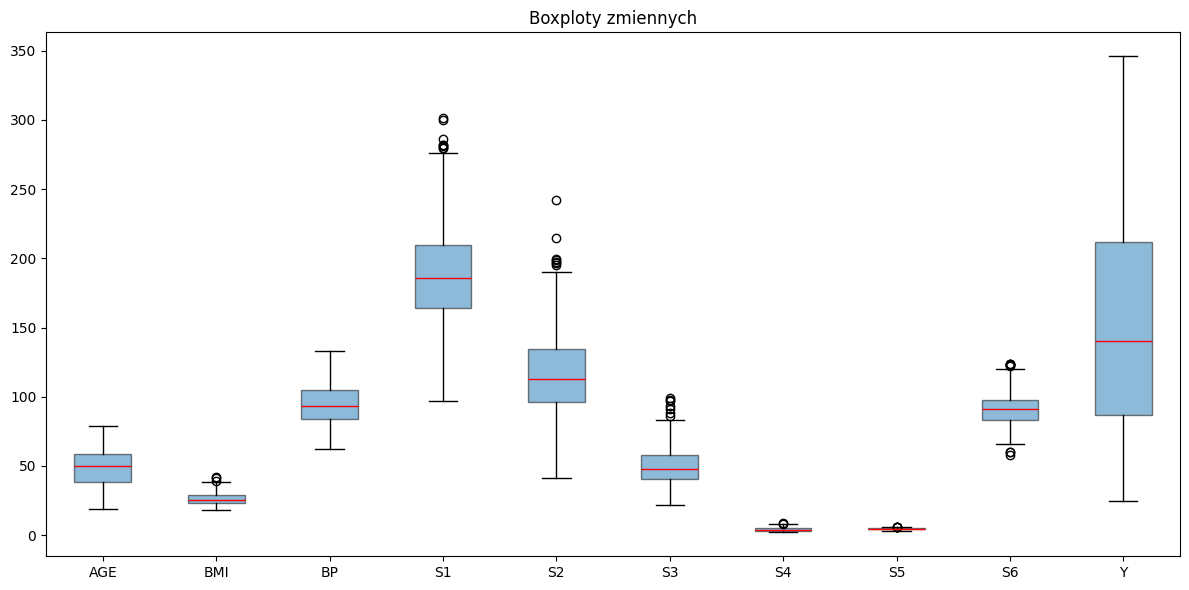

In [106]:
plt.figure(figsize=(12, 6))

plt.boxplot(
    [df2[col] for col in df2.columns],
    tick_labels=df2.columns,
    patch_artist=True,
    boxprops=dict(alpha=0.5),
    medianprops=dict(color='red', linewidth=1)
)

plt.title('Boxploty zmiennych')
plt.tight_layout()
plt.show()

Pacjenci mają średnio 48.5 lat (zakres 19-79), średnie BMI wynosi 26.4 (nadwaga wg WHO), a średnie ciśnienie krwi BP = 94.6 mmHg. Zmienna zależna Y (miara postępu cukrzycy) ma średnią 152.1 i duże odchylenie standardowe (77.1), co wskazuje na znaczne zróżnicowanie pacjentów pod względem przebiegu choroby - zakres wartości wynosi 25-346.
Zmienne S1-S2 (cholesterol całkowity i LDL) mają stosunkowo duże odchylenia standardowe względem średniej, co sugeruje dużą zmienność parametrów lipidowych między pacjentami. Zmienna S5 (logarytm trójglicerydów) ma natomiast bardzo małe odchylenie standardowe (0.52), co wynika z transformacji logarytmicznej wygładzającej rozkład.

Sprawdzenie braków danych 

In [98]:
print(df2.isnull().sum())

AGE    0
BMI    0
BP     0
S1     0
S2     0
S3     0
S4     0
S5     0
S6     0
Y      0
dtype: int64


W danych nie występuja braki.

Sprawdzenie korelacji

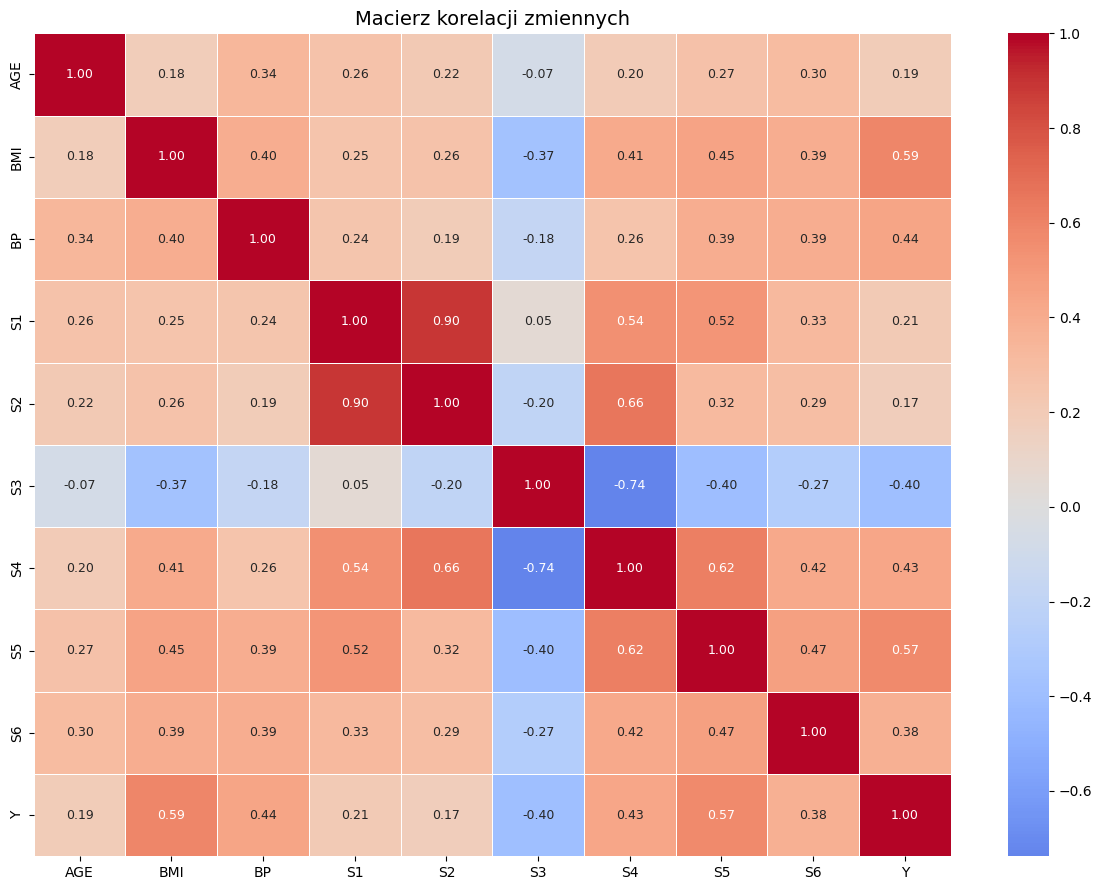


Korelacje zmiennych z Y (target)
BMI    0.586
S5     0.566
BP     0.441
S4     0.430
S3    -0.395
S6     0.382
S1     0.212
AGE    0.188
S2     0.174
Name: Y, dtype: float64


In [108]:
# macierz korelacji
corr_matrix = df2.corr().round(3)

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.zeros_like(corr_matrix, dtype=bool)
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.5,annot_kws={'size': 9})
ax.set_title('Macierz korelacji zmiennych', fontsize=14)
plt.tight_layout()
plt.show()

print('\nKorelacje zmiennych z Y (target)')
print(corr_matrix['Y'].drop('Y').sort_values(key=abs, ascending=False))

Najsilniej skorelowane z Y zmienne to BMI (r = 0.59) i S5 (r = 0.57), co wskazuje je jako głównych predyktorów postępu cukrzycy. Umiarkowaną korelację z Y wykazują również BP (r = 0.44), S4 (r = 0.43) i S3 (r = -0.40). Najsłabiej z Y skorelowane są AGE (r = 0.19) i S2 (r = 0.17).

Wśród zmiennych niezależnych wykryto dwie pary silnie skorelowane:
- S1 - S2 (r = 0.90) - cholesterol całkowity i LDL są niemal liniowo zależne, co jest biologicznie uzasadnione (LDL jest głównym składnikiem cholesterolu całkowitego)
- S3 - S4 (r = -0.74) - HDL i stosunek TCH/HDL są ujemnie skorelowane, co również wynika wprost z definicji tych wskaźników

Obecność tych par sugeruje multikolinearność w modelu pełnym, która zostanie zbadana przy pomocy współczynnika VIF w sekcji redukcji wymiarowości.

### 3.2 Budowa modelu regresji wielorakiej 

In [112]:
features = ['AGE', 'BMI', 'BP', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6']
X = df2[features]
Y = df2['Y']
n = len(Y)
k = len(features)

X_const = sm.add_constant(X)
model = sm.OLS(Y, X_const).fit()


### 3.3 Podsumowanie modelu regresji wielorakiej 

In [113]:
fitted = model.fittedvalues
resid  = model.resid

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.501
Model:                            OLS   Adj. R-squared:                  0.490
Method:                 Least Squares   F-statistic:                     48.11
Date:                Wed, 10 Jun 2026   Prob (F-statistic):           8.80e-60
Time:                        18:40:11   Log-Likelihood:                -2393.7
No. Observations:                 442   AIC:                             4807.
Df Residuals:                     432   BIC:                             4848.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -363.8987     68.142     -5.340      0.0

In [ ]:
RSE = np.sqrt(np.sum(resid**2) / (n - k - 1))
RMSE = np.sqrt(np.mean(resid**2))
R2 = model.rsquared
R2_adj = model.rsquared_adj
AIC = model.aic
BIC = model.bic

print('MIARY DOPASOWANIA')
print(f'R^2: {R2:.4f}  -> model wyjaśnia {R2*100:.1f}% wariancji Y')
print(f'Adj. R^2: {R2_adj:.4f}')
print(f'RSE: {RSE:.4f}')
print(f'RMSE: {RMSE:.4f}')
print(f'AIC: {AIC:.2f}')
print(f'BIC: {BIC:.2f}')
print(f'F-stat: {model.fvalue:.2f}, p = {model.f_pvalue:.2e}')

print("\nResiduals (reszty)")
print(f"Min: {resid.min():.4f}")
print(f"Q1: {resid.quantile(0.25):.4f}")
print(f"Median: {resid.median():.4f}")
print(f"Q3: {resid.quantile(0.75):.4f}")
print(f"Max: {resid.max():.4f}")



MIARY DOPASOWANIA
R^2: 0.5006  → model wyjaśnia 50.1% wariancji Y
Adj. R^2: 0.4902
RSE: 55.0460
RMSE: 54.4197
AIC: 4807.45
BIC: 4848.36
F-stat: 48.11, p = 8.80e-60

Residuals (reszty)
Min: -147.0442
Q1: -39.0281
Median: -4.1669
Q3: 38.2020
Max: 152.4020


**R^2 = 0.501:**<br>
Model wyjaśnia 50.1% zmienności postępu cukrzycy - jest to wynik niezbyt dobry, sugeruje że zmienne środowiskowe i biochemiczne zawarte w zbiorze opisują chorobę tylko częściowo. Pozostałe ~50% zmienności wynika prawdopodobnie z czynników nieuwzględnionych w danych.

**Adj. R^2 = 0.490:**<br>
Skorygowany R^2 jest nieznacznie niższy od R^2, co wskazuje że część zmiennych w modelu nie wnosi istotnego wkładu - zostanie to zbadane w redukcji wymiarowości.

**Istotność współczynników:**<br>
Istotne statystycznie (p < 0.05) są: BMI, BP i S5 oraz wyraz wolny. Zmienne AGE, S1, S2, S3, S4 i S6 są nieistotne (p > 0.05) - są kandydatami do usunięcia z modelu.

**F-statistic = 48.11, p = 8.80e-60:**<br>
Model jako całość jest  istotny statystycznie.

**RSE = 55.05:**<br>
Przeciętny błąd predykcji wynosi ~55 jednostek przy zakresie Y = 25-346 - błąd jest zauważalny.

**Condition Number = 7190:**<br>
Bardzo wysoka wartość potwierdza multikolinearność w modelu - wymaga redukcji zmiennych przez VIF.

**Durbin-Watson = 2.018:**<br>
Wartość bliska 2 wskazuje na brak autokorelacji reszt.

**Jarque-Bera (p = 0.132), Omnibus (p = 0.061):**<br>
Brak podstaw do odrzucenia normalności reszt - założenie normalności jest spełnione.

**Reszty (Residuals):**<br>
Mediana reszt wynosi -4.17, co wskazuje na niewielkie  niedoszacowanie modelu. Rozstęp międzykwartylowy jest symetryczny wokół zera. Natomiast wartości ekstremalne - minimum -147.04 i maksimum 152.40 - są duże w stosunku do zakresu zmiennej Y (25-346) i sugerują obecność obserwacji, które model przewiduje ze błędem.

### 3.4 Sprawdzenie założeń modelu

#### 3.4.1 Normalność reszt - test Shapiro-Wilka i QQ-plot

Test Shapiro-Wilka
- H0: reszty pochodzą z rozkładu normalnego
- H1: reszty nie pochodzą z rozkładu normalnego

In [117]:
stat_sw, p_sw = stats.shapiro(resid)
print(f'W = {stat_sw:.4f}, p-value = {p_sw:.4e}')

W = 0.9952, p-value = 1.8469e-01


p > 0.05, cyzli brak podstaw do odrzucenia H0 

QQ-plot i histogram

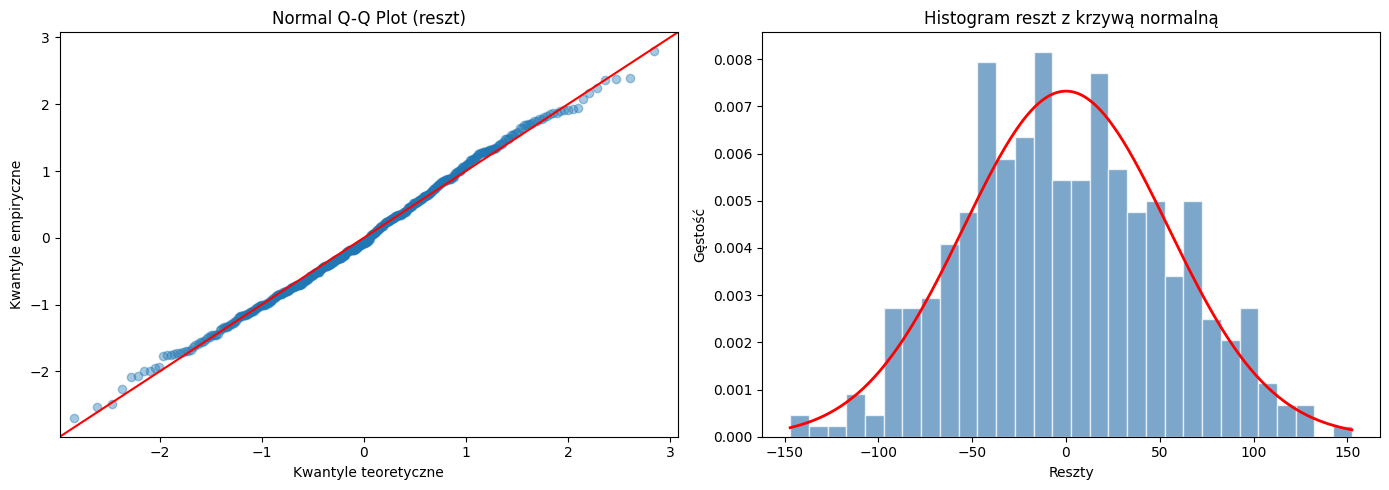

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pp = ProbPlot(resid, fit=True)
pp.qqplot(ax=axes[0], line='45', alpha=0.4, lw=1)
axes[0].set_title('Normal Q-Q Plot (reszt)')
axes[0].set_xlabel('Kwantyle teoretyczne')
axes[0].set_ylabel('Kwantyle empiryczne')

axes[1].hist(resid, bins=30, density=True, color='steelblue', alpha=0.7, edgecolor='white')
x_norm = np.linspace(resid.min(), resid.max(), 200)
axes[1].plot(x_norm, stats.norm.pdf(x_norm, resid.mean(), resid.std()), 'r-', lw=2)
axes[1].set_title('Histogram reszt z krzywą normalną')
axes[1].set_xlabel('Reszty')
axes[1].set_ylabel('Gęstość')

plt.tight_layout()
plt.show()

**QQ-plot:**
Punkty leżą bardzo blisko prostej 45 stopni w całym zakresie kwantyli, co wskazuje na dobrą zgodność reszt z rozkładem normalnym. 

**Histogram:**
Rozkład reszt jest w przybliżeniu symetryczny i zbliżony do dzwonowego kształtu krzywej normalnej. 

Test Shapiro-Wilka nie dał podstaw do odrzucenia H0 o normalności reszt. QQ-plot i histogram potwierdzają ten wynik - założenie normalności reszt jest spełnione.

#### 3.4.2 Brak trendu w resztach - Residuals vs Fitted

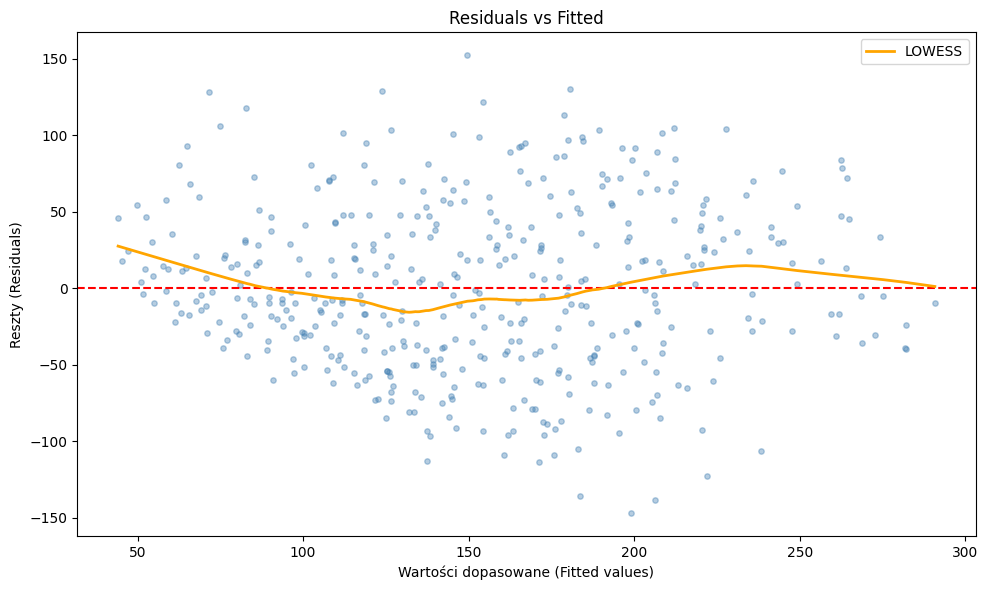

In [120]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(fitted, resid, alpha=0.4, s=15, color='steelblue')
ax.axhline(0, color='red', linestyle='--', linewidth=1.5)
lowess = sm.nonparametric.lowess(resid, fitted, frac=0.3)
ax.plot(lowess[:, 0], lowess[:, 1], color='orange', linewidth=2, label='LOWESS')
ax.set_xlabel('Wartości dopasowane (Fitted values)')
ax.set_ylabel('Reszty (Residuals)')
ax.set_title('Residuals vs Fitted')
ax.legend()
plt.tight_layout()
plt.show()

Linia LOWESS przebiega w pobliżu zera przez większość zakresu wartości dopasowanych, jednak wykazuje lekką falującą krzywizną - reszty są nieznacznie dodatnie dla niskich wartości fitted, ujemne w środkowym zakresie i ponownie bliskie zera dla wysokich. Odchylenia te są jednak niewielkie, a ogólny rozrzut punktów wokół y=0 wydaje się w przybliżeniu losowy. Założenie liniowości jest w większości spełnione, choć lekka nieliniowość w środkowym zakresie może sugerować, że model nie wychwytuje wszystkich zależności w danych.

#### 3.4.3 Ekstrapolacja - przedział wartości, dla których model ma sens

In [123]:
print('PRZEDZIAŁ STOSOWALNOŚCI MODELU')
for f in features:
    print(f'  {f}: [{df2[f].min():.2f}, {df2[f].max():.2f}]')
print(f'Y (target): [{Y.min():.1f}, {Y.max():.1f}]')

PRZEDZIAŁ STOSOWALNOŚCI MODELU
  AGE: [19.00, 79.00]
  BMI: [18.00, 42.20]
  BP: [62.00, 133.00]
  S1: [97.00, 301.00]
  S2: [41.60, 242.40]
  S3: [22.00, 99.00]
  S4: [2.00, 9.09]
  S5: [3.26, 6.11]
  S6: [58.00, 124.00]
Y (target): [25.0, 346.0]


Model jest wiarygodny wyłącznie dla wartości zmiennych w powyższych zakresach. Ekstrapolacja poza te zakresy jest nieuzasadniona.

#### 3.4.4 Liczba obserwacji

In [125]:
print(f"Liczba obserwacji: {len(df2)}")

Liczba obserwacji: 442


Zbiór zawiera 442 obserwacje, zatem warunek minimum 30 na każdą zmienną niezalezną jest spełniony (powinno być min. 270).

#### 3.4.5 Homoskedastyczność 

Scale-Location 

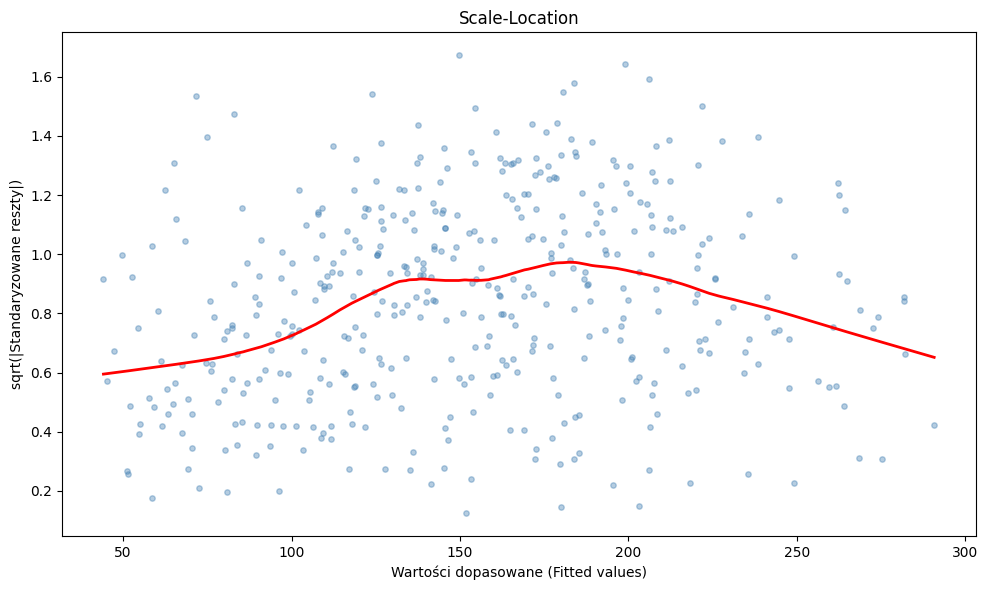

In [126]:
fig, ax = plt.subplots(figsize=(10, 6))
sqrt_abs_resid = np.sqrt(np.abs(resid / resid.std()))
ax.scatter(fitted, sqrt_abs_resid, alpha=0.4, s=15, color='steelblue')
lowess2 = sm.nonparametric.lowess(sqrt_abs_resid, fitted, frac=0.3)
ax.plot(lowess2[:, 0], lowess2[:, 1], color='red', linewidth=2)
ax.set_xlabel('Wartości dopasowane (Fitted values)')
ax.set_ylabel('sqrt(|Standaryzowane reszty|)')
ax.set_title('Scale-Location')
plt.tight_layout()
plt.show()

Test Breusch-Pagana
- H0: wariancja reszt jest stała

In [131]:
bp_lm, bp_p, _, _ = het_breuschpagan(resid, X_const)
print(f'LM = {bp_lm:.4f}, p-value = {bp_p:.4e}')

LM = 24.3084, p-value = 3.8394e-03


Linia LOWESS wykazuje łagodny trend rosnący od wartości ≈0.60 (dla niskich fitted) do ≈0.95 (środkowy zakres), a następnie malejący do ≈0.65 (wysokie fitted). Rozrzut punktów jest w przybliżeniu równomierny przez większość zakresu. Odchylenia linii LOWESS od poziomej są umiarkowane, co sugeruje łagodną heteroskedastyczność. Potwierdza to test Breusch-Pagan, gdzie p < 0.05, czyli hipoteza H0 o stałej wariancji reszt została odzrucona. Zatem zalożenie o homoskedantyczności nie jest spełnione.

#### 3.4.6 Autokorelacja reszt - test Box-Pierce
- H0: brak autokorelacji reszt

In [128]:
for lag in [1, 2, 3]:
    result = acorr_ljungbox(resid, lags=[lag], boxpierce=True, return_df=True)
    stat = result['bp_stat'].values[0]
    pval = result['bp_pvalue'].values[0]
    dec  = 'ODRZUCENIE H0' if pval < 0.05 else 'Brak podstaw do odrzucenia H0'
    print(f'  lag={lag}: Q = {stat:.4f}, p-value = {pval:.4f} -> {dec}')

  lag=1: Q = 0.0501, p-value = 0.8229 -> Brak podstaw do odrzucenia H0
  lag=2: Q = 2.5829, p-value = 0.2749 -> Brak podstaw do odrzucenia H0
  lag=3: Q = 2.8687, p-value = 0.4123 -> Brak podstaw do odrzucenia H0


We wszystkich przypadkach p-value > 0.05, zatem nie ma podstaw do odrzucenia hipotezy zerowej o braku autokorelacji reszt. Założenie o braku autokorelacji reszt jest spełnione.

Podsumowanie modelu pełnego:
Model regresji wielorakiej z 9 zmiennymi niezależnymi wyjaśnia 50.1% zmienności postępu cukrzycy (R^2 = 0.501). Spośród dziewięciu zmiennych jedynie BMI, BP i S5 okazały się istotne statystycznie (p < 0.05), pozostałe sześć zmiennych nie wnosi istotnego wkładu do modelu. Wysoka wartość Condition Number (7190) oraz silne korelacje między S1-S2 i S3-S4 wskazują na multikolinearność, która zaburza estymację współczynników.
Spośród założeń modelu homoskedastyczność jest naruszona (test Breusch-Pagana), a liniowość jedynie w przybliżeniu zachowana. Model wymaga redukcji wymiarowości w celu usunięcia nadmiarowych i skorelowanych zmiennych, co powinno poprawić jego jakość i interpretowalność.

### 3.5 Redukcja wymiarowości

#### 3.5.1 Metoda 1 - VIF (Variance Inflation Factor)

In [132]:
# Jeżeli VIF > 5 -> kandydat do usunięcia
def compute_vif(X_df):
    X_c = sm.add_constant(X_df)
    vif_data = pd.DataFrame()
    vif_data['Zmienna'] = X_df.columns
    vif_data['VIF'] = [variance_inflation_factor(X_c.values, i+1)  for i in range(X_df.shape[1])]
    return vif_data.sort_values('VIF', ascending=False).reset_index(drop=True)

print('VIF - MODEL PEŁNY ')
vif1 = compute_vif(df2[features])
print(vif1.to_string(index=False))


VIF - MODEL PEŁNY 
Zmienna       VIF
     S1 59.062508
     S2 39.123245
     S3 15.369272
     S5 10.075391
     S4  8.833675
    BMI  1.478660
     S6  1.476845
     BP  1.407578
    AGE  1.205380


In [138]:
features_vif = features.copy()

# usunięcie S1
features_vif.remove('S1')

print("VIF po usunięciu S1")
vif_s1 = compute_vif(df2[features_vif])
print(vif_s1.to_string(index=False))

VIF po usunięciu S1
Zmienna      VIF
     S4 7.782849
     S3 3.615896
     S2 2.925747
     S5 2.146975
     S6 1.476488
    BMI 1.472896
     BP 1.406432
    AGE 1.204720


In [139]:
# usunięcie S4
features_vif.remove('S4')

print("\nVIF po usunięciu S4")
vif_s4 = compute_vif(df2[features_vif])
print(vif_s4.to_string(index=False))


VIF po usunięciu S4
Zmienna      VIF
     S5 1.628590
     S6 1.467872
    BMI 1.467552
     BP 1.399175
     S3 1.270696
    AGE 1.204422
     S2 1.177056


In [140]:
print("\nKońcowy zestaw zmiennych:")
print(features_vif)


Końcowy zestaw zmiennych:
['AGE', 'BMI', 'BP', 'S2', 'S3', 'S5', 'S6']


#### 3.5.2 Metoda 2 - Regresja krokowa w przód (Forward Stepwise)

In [141]:
def forward_stepwise(X_df, y, threshold_in=0.05):
    included = []
    remaining = list(X_df.columns)
    print('REGRESJA KROKOWA W PRZÓD (Forward Stepwise)')
    print(f'Próg p-value: {threshold_in}')
    step = 1
    while remaining:
        pvals = {}
        for candidate in remaining:
            cols = included + [candidate]
            X_c = sm.add_constant(X_df[cols])
            m = sm.OLS(y, X_c).fit()
            pvals[candidate] = m.pvalues[candidate]
        best = min(pvals, key=pvals.get)
        if pvals[best] < threshold_in:
            included.append(best)
            remaining.remove(best)
            print(f'Krok {step}: dodano {best} (p={pvals[best]:.4f})')
            step += 1
        else:
            print(f'Krok {step}: żadna zmienna nie spełnia progu (min p={pvals[best]:.4f}). Stop.')
            break
    return included

features_fwd = forward_stepwise(df2[features], Y)
print(f'\nWybrane zmienne (forward): {features_fwd}')

REGRESJA KROKOWA W PRZÓD (Forward Stepwise)
Próg p-value: 0.05
Krok 1: dodano BMI (p=0.0000)
Krok 2: dodano S5 (p=0.0000)
Krok 3: dodano BP (p=0.0000)
Krok 4: dodano S1 (p=0.0015)
Krok 5: dodano S2 (p=0.0147)
Krok 6: żadna zmienna nie spełnia progu (min p=0.4718). Stop.

Wybrane zmienne (forward): ['BMI', 'S5', 'BP', 'S1', 'S2']


#### 3.5.3 Metoda 3 - Regresja krokowa wstecz (Backward Stepwise)

In [143]:
def backward_stepwise(X_df, y, threshold_out=0.05):
    included = list(X_df.columns)
    print('REGRESJA KROKOWA WSTECZ (Backward Stepwise)')
    print(f'Próg p-value: {threshold_out}')
    step = 1
    while True:
        X_c = sm.add_constant(X_df[included])
        m = sm.OLS(y, X_c).fit()
        pvals = m.pvalues.drop('const')
        worst = pvals.idxmax()
        if pvals[worst] > threshold_out:
            included.remove(worst)
            print(f'  Krok {step}: usunięto {worst} (p={pvals[worst]:.4f})')
            step += 1
        else:
            print(f'  Krok {step}: wszystkie zmienne istotne (max p={pvals[worst]:.4f}). Stop.')
            break
    return included

features_bwd = backward_stepwise(df2[features], Y)
print(f'\nWybrane zmienne (backward): {features_bwd}')

REGRESJA KROKOWA WSTECZ (Backward Stepwise)
Próg p-value: 0.05
  Krok 1: usunięto AGE (p=0.5833)
  Krok 2: usunięto S3 (p=0.5295)
  Krok 3: usunięto S4 (p=0.6327)
  Krok 4: usunięto S6 (p=0.4718)
  Krok 5: wszystkie zmienne istotne (max p=0.0147). Stop.

Wybrane zmienne (backward): ['BMI', 'BP', 'S1', 'S2', 'S5']


#### 3.5.4 Porównanie wszystkich modeli zredukowanych

In [145]:
def model_metrics(feat_list, label):
    X_c = sm.add_constant(df2[feat_list])
    m = sm.OLS(Y, X_c).fit()
    p = len(feat_list)
    rse  = np.sqrt(np.sum(m.resid**2) / (n - p - 1))
    rmse = np.sqrt(np.mean(m.resid**2))
    return {'Model': label, 'Zm.': p,
            'R^2': round(m.rsquared, 4),
            'Adj.R^2': round(m.rsquared_adj, 4),
            'RSE': round(rse, 4),
            'RMSE': round(rmse, 4),
            'AIC': round(m.aic, 2)}

results = pd.DataFrame([
    model_metrics(features, 'Pełny (9 zm.)'),
    model_metrics(features_vif, f'VIF ({len(features_vif)} zm.)'),
    model_metrics(features_fwd, f'Forward ({len(features_fwd)} zm.)'),
    model_metrics(features_bwd, f'Backward ({len(features_bwd)} zm.)'),
])
 
print(results.to_string(index=False))

           Model  Zm.    R^2  Adj.R^2     RSE    RMSE     AIC
   Pełny (9 zm.)    9 0.5006   0.4902 55.0460 54.4197 4807.45
     VIF (7 zm.)    7 0.4973   0.4891 55.1018 54.6008 4806.38
 Forward (5 zm.)    5 0.4989   0.4932 54.8842 54.5104 4800.92
Backward (5 zm.)    5 0.4989   0.4932 54.8842 54.5104 4800.92


Wszystkie trzy metody redukcji dały zbliżone wyniki - R^2 pozostaje na poziomie ~0.499 niezależnie od liczby zmiennych, co oznacza że usunięte zmienne nie wnosiły istotnej informacji do modelu.
Metody forward i backward zgodnie wskazały ten sam zestaw 5 zmiennych: BMI, BP, S1, S2, S5, osiągając najlepsze AIC = 4800.92 przy najmniejszej liczbie zmiennych. Model VIF zachował 7 zmiennych uzyskując AIC = 4806.38, nieznacznie gorsze od modelu 5-zmiennego.
Jako model optymalny wybrany zostaje wynik regresji krokowej (forward/backward) z 5 zmiennymi - osiąga porównywalny Adj.R^2 (0.4932) do modelu pełnego (0.4902) przy czym jest o 4 zmienne mniej (prostszy model o podobnej jakości jest lepszy).

### 3.6 Wykresy diagnostyczne i wartości odstające

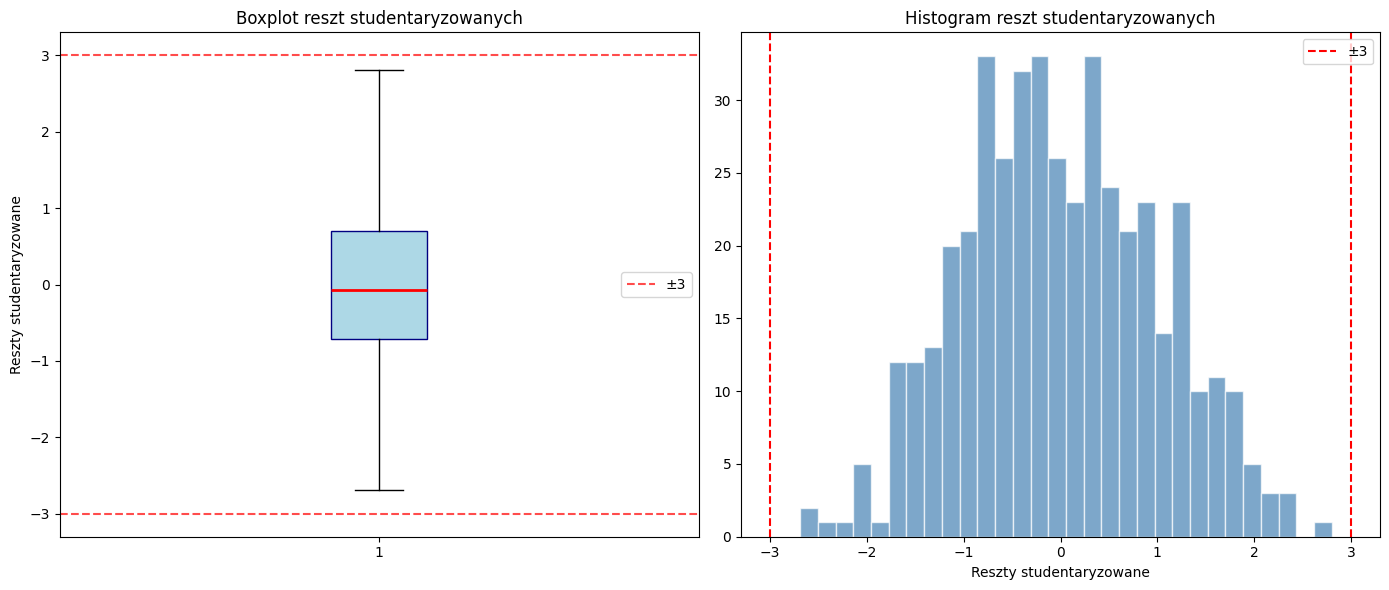

Obserwacje odstające (|std_resid| > 3): 0 (0.00%)


In [146]:
influence = model.get_influence()
std_resid  = influence.resid_studentized_internal   # reszty studentaryzowane
hat_values = influence.hat_matrix_diag # leverage
cooks_d = influence.cooks_distance[0] # odległość Cook'a

# boxplot + histogram standaryzowanych reszt
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].boxplot(std_resid, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='navy'),
                medianprops=dict(color='red', linewidth=2),
                flierprops=dict(marker='o', markersize=4, alpha=0.5))
axes[0].axhline(3,  color='red', linestyle='--', alpha=0.7, label='±3')
axes[0].axhline(-3, color='red', linestyle='--', alpha=0.7)
axes[0].set_title('Boxplot reszt studentaryzowanych')
axes[0].set_ylabel('Reszty studentaryzowane')
axes[0].legend()

axes[1].hist(std_resid, bins=30, color='steelblue', alpha=0.7, edgecolor='white')
axes[1].axvline(3,  color='red', linestyle='--', label='±3')
axes[1].axvline(-3, color='red', linestyle='--')
axes[1].set_title('Histogram reszt studentaryzowanych')
axes[1].set_xlabel('Reszty studentaryzowane')
axes[1].legend()

plt.tight_layout()
plt.show()

n_out = np.sum(np.abs(std_resid) > 3)
print(f'Obserwacje odstające (|std_resid| > 3): {n_out} ({n_out/n*100:.2f}%)')

Wszystkie reszty studentaryzowane mieszczą się w przedziale (−3, 3) - żadna obserwacja nie jest odstająca według tego kryterium. Model nie popełnia ekstremalnych błędów predykcji dla żadnej obserwacji.

### 3.7 Wartości wpływowe - Cook's Distance, DFBETAS, DFFITS

Cook's Distance 

Próg Cook'a = 0.00926


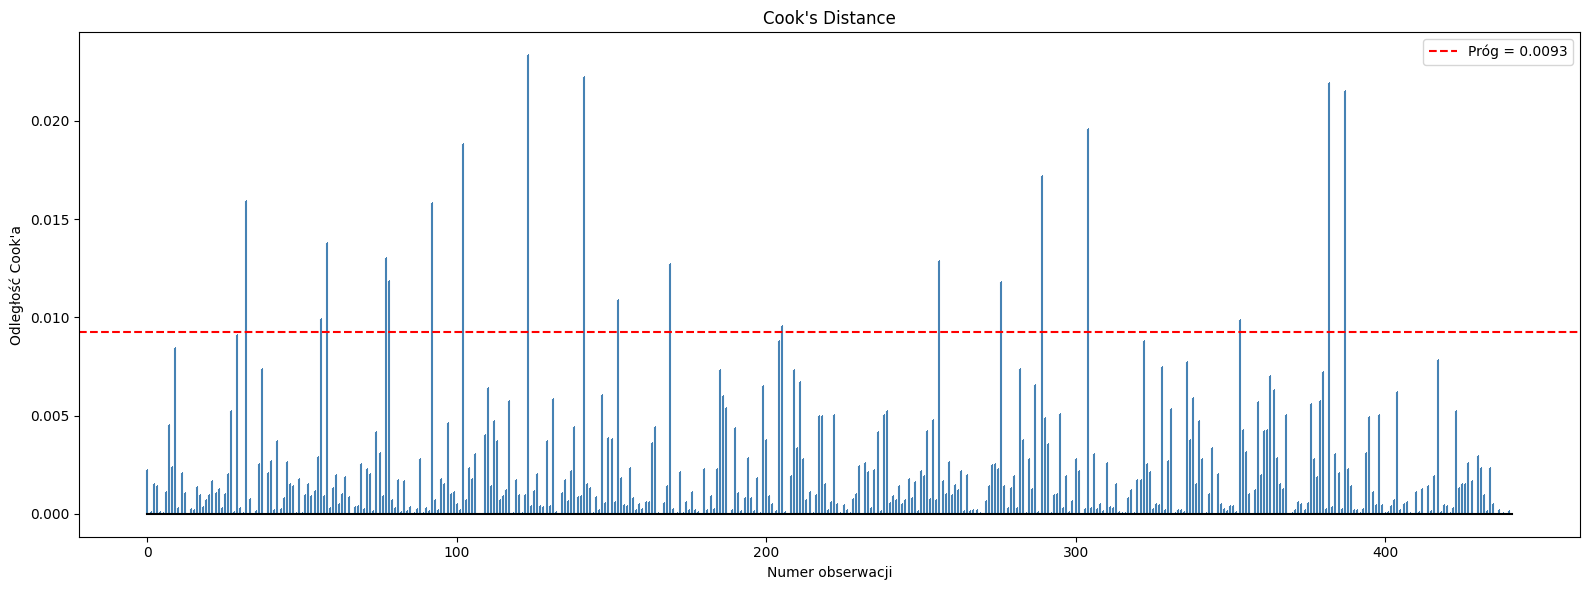

Obserwacje wpływowe: 19 (4.30%)


In [151]:
cook_threshold = 4 / (n - k - 1)
print(f"Próg Cook'a = {cook_threshold:.5f}")

plt.figure(figsize=(16, 6))

plt.stem(np.arange(n), cooks_d, markerfmt=',', linefmt='steelblue', basefmt='black')
plt.axhline(cook_threshold, color='red', linestyle='--', lw=1.5, label=f'Próg = {cook_threshold:.4f}')

plt.xlabel('Numer obserwacji')
plt.ylabel("Odległość Cook'a")
plt.title("Cook's Distance")
plt.legend()

plt.tight_layout()
plt.show()

influential_mask = cooks_d > cook_threshold
print(f"Obserwacje wpływowe: {influential_mask.sum()} ({influential_mask.sum()/n*100:.2f}%)")

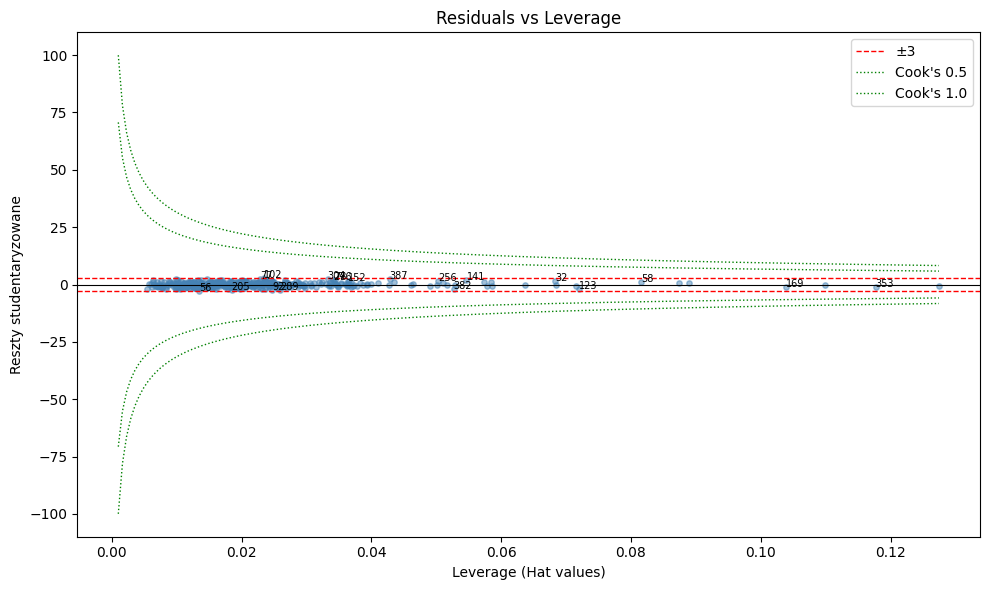

In [149]:
# Residuals vs Leverage 
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(hat_values, std_resid, alpha=0.5, s=15, color='steelblue')
ax.axhline(0,color='black', lw=0.8)
ax.axhline(3, color='red', linestyle='--', lw=1, label='±3')
ax.axhline(-3, color='red', linestyle='--', lw=1)
h_range = np.linspace(0.001, hat_values.max(), 200)
for cl in [0.5, 1.0]:
    cl_line = np.sqrt(cl * (k+1) * (1 - h_range) / h_range)
    ax.plot(h_range,  cl_line, 'g:', lw=1, label=f"Cook's {cl}")
    ax.plot(h_range, -cl_line, 'g:', lw=1)
# etykiety dla wpływowych
for i in np.where(influential_mask)[0]:
    ax.annotate(str(i), (hat_values[i], std_resid[i]), fontsize=7)
ax.set_xlabel('Leverage (Hat values)')
ax.set_ylabel('Reszty studentaryzowane')
ax.set_title('Residuals vs Leverage')
ax.legend()
plt.tight_layout()
plt.show()

Wszystkie obserwacje mają bardzo małe wartości leverage (zakres 0-0.13). Żadna obserwacja nie przekracza linii Cook'a 0.5 ani 1.0, jednak kilkanaście obserwacji zostało oznaczonych etykietami jako kandydaci wpływowi.

Cook's Distance: próg = 0.00942. Spośród 442 obserwacji 19 (4.30%) przekracza ten próg, co kwalifikuje je jako obserwacje wpływowe. Wartości Cook'a są jednak niewielkie - żadna nie zbliża się do 0.5 ani 1.0, co oznacza że wpływ poszczególnych obserwacji jest umiarkowany, ale ich łączna liczba uzasadnia usunięcie i sprawdzenie czy model się poprawi.

DFBETAS 

Próg DFBETAS: 2/sqrt(n) = 0.0951


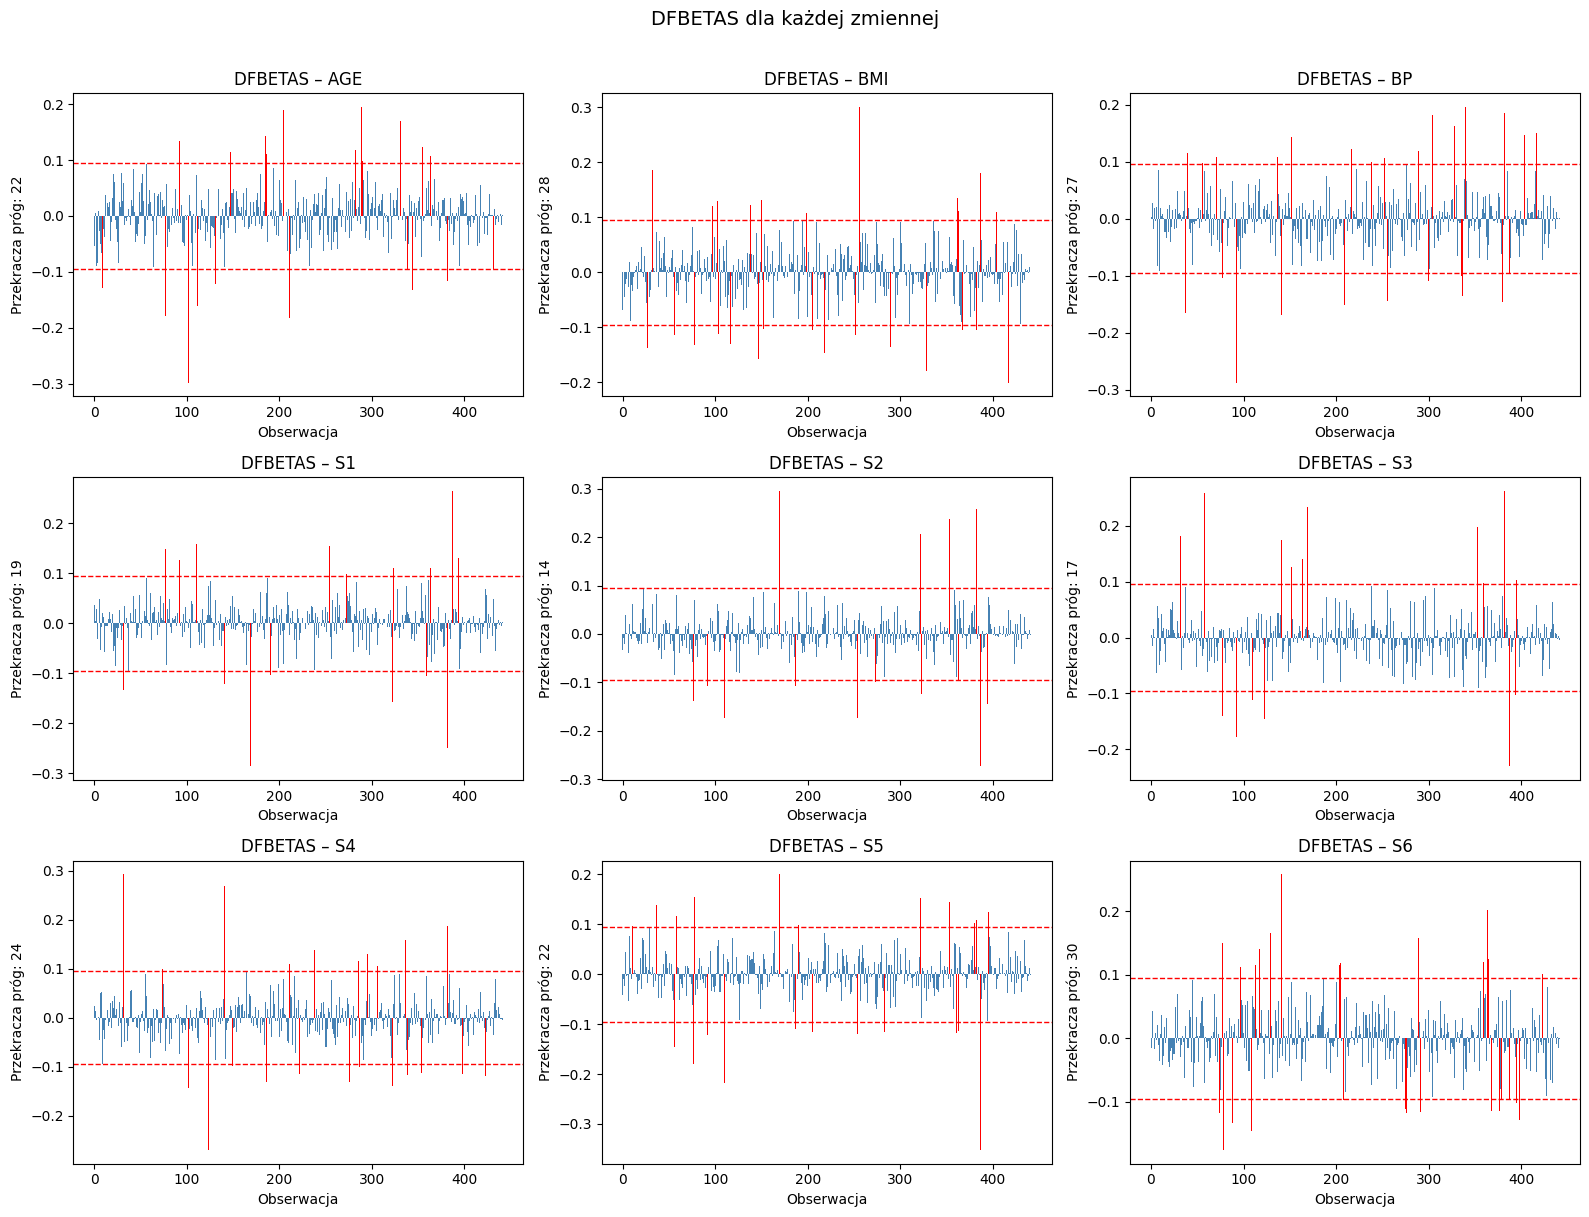

In [ ]:
dfbetas = influence.dfbetas  
dfbetas_threshold = 2 / np.sqrt(n)
print(f'Próg DFBETAS: 2/sqrt(n) = {dfbetas_threshold:.4f}')

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

coef_names = ['const'] + features
for idx, (ax, fname) in enumerate(zip(axes, coef_names[1:])):
    db = dfbetas[:, idx+1]
    colors_db = ['red' if abs(v) > dfbetas_threshold else 'steelblue' for v in db]
    ax.bar(np.arange(n), db, color=colors_db, width=1.0)
    ax.axhline( dfbetas_threshold, color='red', linestyle='--', lw=1)
    ax.axhline(-dfbetas_threshold, color='red', linestyle='--', lw=1)
    ax.set_title(f'DFBETAS - {fname}')
    ax.set_xlabel('Obserwacja')
    n_exceed = np.sum(np.abs(db) > dfbetas_threshold)
    ax.set_ylabel(f'Przekracza próg: {n_exceed}')

plt.suptitle('DFBETAS dla każdej zmiennej', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

Próg = 0.095. Liczba obserwacji przekraczających próg różni się w zależności od zmiennej - od 14 (S2) do 30 (S6). Najczęściej wpływowe obserwacje pojawiają się dla zmiennych BMI (28), S6 (30) i BP (27), co sugeruje że te zmienne są najbardziej wrażliwe na obecność pojedynczych obserwacji. Większość przekroczeń jest jednak nieznaczna - wartości DFBETAS rzadko przekraczają 0.2, a te same obserwacje powtarzają się dla wielu zmiennych.

DFFITS 

Próg DFFITS: 2*sqrt((k+1)/n) = 0.3008


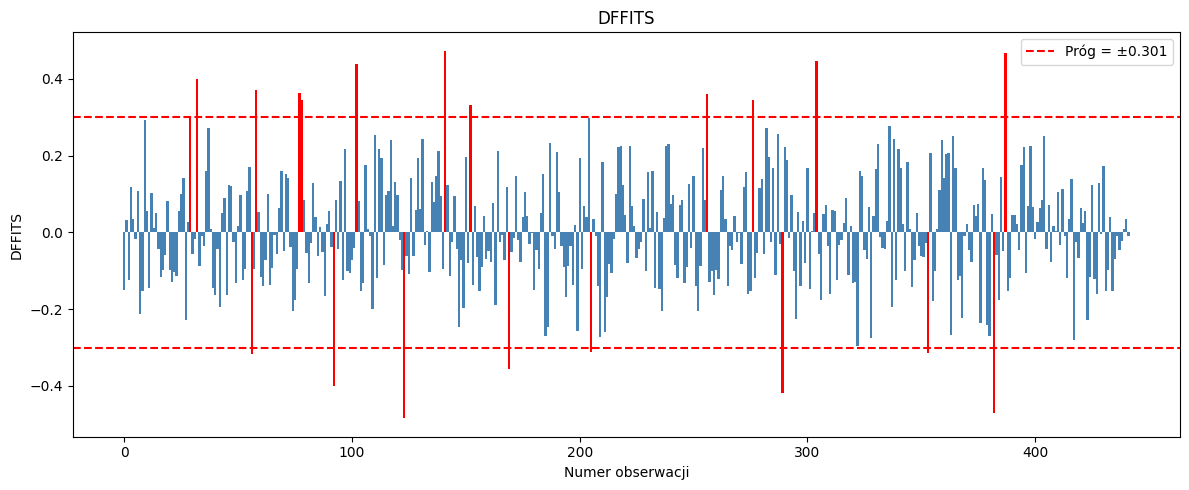

Obserwacje przekraczające próg DFFITS: 20 (4.52%)


In [153]:
dffits_vals, _ = influence.dffits
dffits_threshold = 2 * np.sqrt((k + 1) / n)
print(f'Próg DFFITS: 2*sqrt((k+1)/n) = {dffits_threshold:.4f}')

fig, ax = plt.subplots(figsize=(12, 5))
colors_df = ['red' if abs(v) > dffits_threshold else 'steelblue' for v in dffits_vals]
ax.bar(np.arange(n), dffits_vals, color=colors_df, width=1.0)
ax.axhline( dffits_threshold, color='red', linestyle='--', lw=1.5,
            label=f'Próg = ±{dffits_threshold:.3f}')
ax.axhline(-dffits_threshold, color='red', linestyle='--', lw=1.5)
ax.set_xlabel('Numer obserwacji')
ax.set_ylabel('DFFITS')
ax.set_title('DFFITS')
ax.legend()
plt.tight_layout()
plt.show()

n_dffits = np.sum(np.abs(dffits_vals) > dffits_threshold)
print(f'Obserwacje przekraczające próg DFFITS: {n_dffits} ({n_dffits/n*100:.2f}%)')

Próg = 0.301. Spośród 442 obserwacji 20 (4.52%) przekracza ten próg. Kilka obserwacji osiąga wartości DFFITS rzędu +/-0.4, co wskazuje że ich usunięcie zmieniłoby wartości dopasowane o ok. 0.4-0.5 odchylenia standardowego - jest to umiarkowany wpływ. Wyniki są spójne z Cook's Distance (podobna liczba i rozkład obserwacji wpływowych).

Reszty studentaryzowane

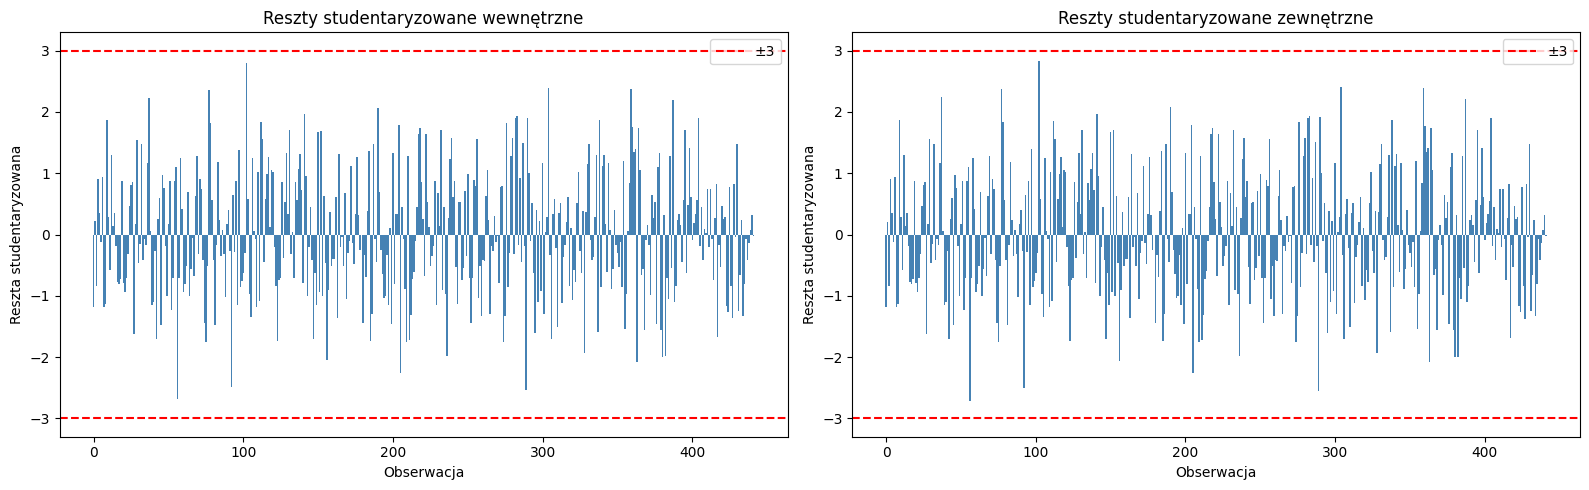

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Wewnętrzne
axes[0].bar(np.arange(n), std_resid,
            color=['red' if abs(v) > 3 else 'steelblue' for v in std_resid], width=1.0)
axes[0].axhline( 3, color='red', linestyle='--', lw=1.5, label='±3')
axes[0].axhline(-3, color='red', linestyle='--', lw=1.5)
axes[0].set_title('Reszty studentaryzowane wewnętrzne')
axes[0].set_xlabel('Obserwacja')
axes[0].set_ylabel('Reszta studentaryzowana')
axes[0].legend()

# Zewnętrzne
ext_resid = influence.resid_studentized_external
axes[1].bar(np.arange(n), ext_resid,
            color=['red' if abs(v) > 3 else 'steelblue' for v in ext_resid], width=1.0)
axes[1].axhline( 3, color='red', linestyle='--', lw=1.5, label='±3')
axes[1].axhline(-3, color='red', linestyle='--', lw=1.5)
axes[1].set_title('Reszty studentaryzowane zewnętrzne')
axes[1].set_xlabel('Obserwacja')
axes[1].set_ylabel('Reszta studentaryzowana')
axes[1].legend()

plt.tight_layout()
plt.show()


Zarówno reszty wewnętrzne jak i zewnętrzne mieszczą się w przedziale (-3, 3) dla wszystkich obserwacji, co potwierdza brak wartości odstających. Rozkład reszt jest równomierny i losowy wzdłuż całego zbioru. Reszty zewnętrzne są niemal identyczne z wewnętrznymi.

### 3.8 Nowy model po usunięciu obserwacji wpływowych

In [155]:
# usuniecie obserwacji wpływowych (Cook's D > próg)
df_clean = df2[~influential_mask].copy().reset_index(drop=True)
print(f'Obserwacje przed: {n}')
print(f'Obserwacje po: {len(df_clean)}')
print(f'Usunięto: {n - len(df_clean)}')

X2 = df_clean[features]
Y2 = df_clean['Y']
n2 = len(Y2)
X2_c = sm.add_constant(X2)
model2 = sm.OLS(Y2, X2_c).fit()
RSE2 = np.sqrt(np.sum(model2.resid**2) / (n2 - k - 1))
RMSE2 = np.sqrt(np.mean(model2.resid**2))

print('\n PORÓWNANIE: PEŁNY vs PO USUNIĘCIU WPŁYWOWYCH')
comp = pd.DataFrame({
    'Miara':  ['R^2', 'Adj.R^2', 'RSE', 'RMSE', 'AIC'],
    'Model 1 (pełny)': [round(R2,4), round(R2_adj,4),
                        round(RSE,4), round(RMSE,4), round(AIC,2)],
    'Model 2 (bez wpływowych)': [round(model2.rsquared,4),
                                  round(model2.rsquared_adj,4),
                                  round(RSE2,4), round(RMSE2,4),
                                  round(model2.aic,2)]
})
print(comp.to_string(index=False))

Obserwacje przed: 442
Obserwacje po: 423
Usunięto: 19

 PORÓWNANIE: PEŁNY vs PO USUNIĘCIU WPŁYWOWYCH
  Miara  Model 1 (pełny)  Model 2 (bez wpływowych)
    R^2           0.5006                    0.5515
Adj.R^2           0.4902                    0.5417
    RSE          55.0460                   51.0211
   RMSE          54.4197                   50.4144
    AIC        4807.4500                 4536.9800


In [168]:
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.551
Model:                            OLS   Adj. R-squared:                  0.542
Method:                 Least Squares   F-statistic:                     56.42
Date:                Wed, 10 Jun 2026   Prob (F-statistic):           1.76e-66
Time:                        20:59:14   Log-Likelihood:                -2258.5
No. Observations:                 423   AIC:                             4537.
Df Residuals:                     413   BIC:                             4577.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -339.5127     69.601     -4.878      0.0

Po usunięciu 19 obserwacji wpływowych (4.30% zbioru) model uległ poprawie we wszystkich metrykach - R^2 wzrósł z 0.501 do 0.552, RSE spadł z 55.05 do 51.02, a AIC zmniejszył się o ~270. Świadczy to o tym, że usunięte obserwacje rzeczywiście zaburzały dopasowanie modelu.

Sprawdzenie VIF dla modelu po usunięciu wpływowych

In [156]:
print(compute_vif(df_clean[features]).to_string(index=False))

Zmienna       VIF
     S1 69.694068
     S2 44.604148
     S3 17.945217
     S5 10.610332
     S4  9.395579
    BMI  1.518930
     S6  1.483798
     BP  1.443231
    AGE  1.215126


VIF po usunięciu wpływowych nadal wskazuje na poważną multikolinearność - S1 (VIF=69.7) i S2 (VIF=44.6) są skrajnie skorelowane, S3 (17.9), S5 (10.6) i S4 (9.4) przekraczają próg 5. Problem multikolinearności nie zniknął po usunięciu wpływowych - model wymaga osobnej redukcji zmiennych.


In [163]:
features_vif2 = features.copy()

# usunięcie S1
features_vif2.remove('S1')

print("VIF po usunięciu S1")
vif_s1 = compute_vif(df_clean[features_vif2])
print(vif_s1.to_string(index=False))

VIF po usunięciu S1
Zmienna      VIF
     S4 7.889951
     S3 3.633996
     S2 2.917471
     S5 2.307573
    BMI 1.518770
     S6 1.483795
     BP 1.438534
    AGE 1.215100


In [164]:
# usunięcie S4
features_vif2.remove('S4')

print("\nVIF po usunięciu S4")
vif_s4 = compute_vif(df_clean[features_vif2])
print(vif_s4.to_string(index=False))


VIF po usunięciu S4
Zmienna      VIF
     S5 1.725288
    BMI 1.510380
     S6 1.479590
     BP 1.431572
     S3 1.270170
    AGE 1.215019
     S2 1.195875


Forward/Backward na czystym zbiorze

In [159]:
features_fwd2 = forward_stepwise(df_clean[features], Y2)
features_bwd2 = backward_stepwise(df_clean[features], Y2)

REGRESJA KROKOWA W PRZÓD (Forward Stepwise)
Próg p-value: 0.05
Krok 1: dodano S5 (p=0.0000)
Krok 2: dodano BMI (p=0.0000)
Krok 3: dodano BP (p=0.0000)
Krok 4: dodano S1 (p=0.0001)
Krok 5: żadna zmienna nie spełnia progu (min p=0.1003). Stop.
REGRESJA KROKOWA WSTECZ (Backward Stepwise)
Próg p-value: 0.05
  Krok 1: usunięto S4 (p=0.9995)
  Krok 2: usunięto S3 (p=0.8173)
  Krok 3: usunięto S6 (p=0.6397)
  Krok 4: usunięto AGE (p=0.6475)
  Krok 5: usunięto S2 (p=0.1003)
  Krok 6: wszystkie zmienne istotne (max p=0.0001). Stop.


In [165]:
def model_metrics_df(dataframe, feat_list, label):
    n_r = len(dataframe)
    X_c = sm.add_constant(dataframe[feat_list])
    m = sm.OLS(dataframe['Y'], X_c).fit()
    p = len(feat_list)
    rse  = np.sqrt(np.sum(m.resid**2) / (n_r - p - 1))
    rmse = np.sqrt(np.mean(m.resid**2))
    return {'Model': label, 'Zm.': p,
            'R^2': round(m.rsquared, 4),
            'Adj.R^2': round(m.rsquared_adj, 4),
            'RSE': round(rse, 4),
            'RMSE': round(rmse, 4),
            'AIC': round(m.aic, 2)}

In [166]:
results2 = pd.DataFrame([
    model_metrics_df(df_clean, features, 'Bez wpływowych - pełny'),
    model_metrics_df(df_clean, features_vif2, f'Bez wpływowych - VIF ({len(features_vif2)} zm.)'),
    model_metrics_df(df_clean, features_fwd2, f'Bez wpływowych - Forward ({len(features_fwd2)} zm.)'),
    model_metrics_df(df_clean, features_bwd2, f'Bez wpływowych - Backward ({len(features_bwd2)} zm.)'),
])
print(results2.to_string(index=False))

                            Model  Zm.    R^2  Adj.R^2     RSE    RMSE     AIC
           Bez wpływowych - pełny    9 0.5515   0.5417 51.0211 50.4144 4536.98
     Bez wpływowych - VIF (7 zm.)    7 0.5506   0.5430 50.9491 50.4650 4533.83
 Bez wpływowych - Forward (4 zm.)    4 0.5480   0.5437 50.9092 50.6075 4530.21
Bez wpływowych - Backward (4 zm.)    4 0.5480   0.5437 50.9092 50.6075 4530.21


Wszystkie modele zredukowane osiągają zbliżone wyniki. Najlepsze AIC uzyskują modele Forward i Backward (4 zmienne, AIC=4530.21), co czyni je modelami optymalnymi - przy o 5 zmiennych mniej osiągają praktycznie identyczny Adj.R^2 (0.5437) co model pełny (0.5417), a nawet nieznacznie wyższy. Model VIF (7 zmiennych) plasuje się pośrodku z AIC=4533.83.

## 4. Wnioski i podsumowanie

Model regresji wielorakiej dla danych Diabetes osiągnął umiarkowane dopasowanie - R^2 modelu pełnego wynosi 0.501, co oznacza że uwzględnione zmienne biochemiczne i demograficzne wyjaśniają jedynie połowę zmienności postępu cukrzycy. Jest to wynik zrozumiały biorąc pod uwagę złożoność choroby - wiele istotnych czynników (genetyka, dieta, farmakoterapia) nie jest uwzględnionych w zbiorze.


Spośród 9 zmiennych ciągłych jedynie BMI, BP i S5 (log trójglicerydów) okazały się istotne statystycznie w modelu pełnym. Obie metody regresji krokowej (forward i backward) zgodnie wskazały ten sam zestaw 4 zmiennych jako optymalny, co świadczy o stabilności selekcji.


Spełnienie założeń:
- Normalność reszt - spełniona (Shapiro-Wilk p > 0.05, QQ-plot bez odchyleń)
- Brak autokorelacji - spełniony (Box-Pierce p > 0.05, DW ≈ 2)
- Homoskedastyczność - naruszona (Breusch-Pagan p < 0.05), heteroskedastyczność wpływa na precyzję przedziałów ufności
- Multikolinearność - poważna w modelu pełnym, usunięta dopiero po redukcji wymiarowości
- Liniowość - w przybliżeniu zachowana


Usunięcie 19 obserwacji wpływowych (4.30%) wykrytych metodą Cook'a przyniosło poprawę modelu - R^2 wzrósł z 0.501 do 0.552, RSE spadł z 55.05 do 51.02. Analiza DFBETAS i DFFITS potwierdziła spójny zestaw wpływowych obserwacji wykryty wszystkimi metodami.


Za model optymalny uznaje się model po usunięciu obserwacji wpływowych z redukcją do 4 zmiennych (forward/backward stepwise) osiągający Adj.R^2 = 0.544, RSE = 50.91 i AIC = 4530.21 - najlepsze AIC przy najmniejszej liczbie zmiennych. W porównaniu z modelem pełnym jest prostszy, pozbawiony multikolinearności i lepiej dopasowany.


Ograniczenia:
Model jest stosowalny wyłącznie w zakresach zmiennych obserwowanych w danych. Utrzymująca się heteroskedastyczność sugeruje że zależność między zmiennymi a postępem cukrzycy może mieć charakter częściowo nieliniowy - rozważenie transformacji zmiennych lub modelu nieliniowego mogłoby poprawić dopasowanie.